# Customer Segmentation for an Online Retailer
### AIM Capstone Project: Clustering (Unsupervised Learning)

**Author:** Frederick Halog

---

## Dataset source and citation

This project uses the **Online Retail II** dataset from the UCI Machine Learning Repository.

- **Dataset page:** https://archive.ics.uci.edu/dataset/502/online+retail+ii
- **What it is:** every sales transaction of a UK-based online gift-ware shop between 1 December 2009 and 9 December 2011. Many of its customers are wholesalers.
- **Licence:** Creative Commons Attribution 4.0 International (CC BY 4.0). The data may be shared and adapted as long as credit is given.

**Please cite as:**

> Chen, D. (2012). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D

**Related paper by the dataset's author:**

> Chen, D., Sain, S. L., & Guo, K. (2012). Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining. *Journal of Database Marketing & Customer Strategy Management*, 19(3), 197–208.

## How to read this notebook

The notebook follows the capstone steps in order. Each section starts with a short plain-English note on **what we are doing and why**, followed by the code, followed by **what we found**.

| Section | What happens |
|---|---|
| Step 1 | Define the problem and how we will judge success |
| Step 2 | Load the data and get to know it |
| Step 3 | Clean the data, explore it, and build customer features |
| Step 4 | Build and compare clustering models |
| Step 5 | Explain the results and check for bias and fairness |

---
# Step 1: Problem Understanding and Framing

## The business problem, in plain words

The shop has thousands of customers, and today they are all treated the same way: same emails, same offers, same level of attention. But customers are not the same. A wholesaler who orders every week is very different from someone who bought one Christmas gift two years ago.

Treating everyone the same wastes money in two ways:

1. **Discounts go to people who would have bought anyway.**
2. **The best customers and the customers about to leave get no special attention.**

**Goal:** sort customers into a small number of groups ("segments") of people who behave alike, so the marketing team can talk to each group differently.

## The data science problem

| Question | Answer |
|---|---|
| **Type of task** | **Clustering** (unsupervised learning) |
| **Why clustering?** | Nobody has labelled the customers in advance. There is no "right answer" column to learn from, so the computer has to find the natural groups on its own. |
| **What gets grouped?** | Individual customers (one row per customer) |
| **Grouped by what?** | Buying behaviour. The core is **RFM**, a well-known marketing recipe: **R**ecency (how recently they bought), **F**requency (how often they buy), and **M**onetary value (how much they spend). We add a few extras such as order size and how often they return items. |
| **Methods we will compare** | K-Means, Hierarchical clustering, and DBSCAN |

**Problem statement:**

> *Using two years of transaction history, group the shop's customers into a handful of clearly different, easy-to-describe segments based on their buying behaviour, so that each segment can be given its own marketing and service approach.*

## How we will measure success

Because there is no "right answer" to check against, we judge the groups on how tidy and how useful they are.

### Technical measures (is the grouping good?)

| Measure | What it tells us, in plain words | Good looks like |
|---|---|---|
| **Silhouette Score** (main measure) | Is each customer closer to their own group than to the next nearest group? Ranges from -1 to 1. | Higher is better |
| **Davies-Bouldin Index** | How much do the groups overlap? | Lower is better |
| **Calinski-Harabasz Index** | Are the groups tight on the inside and far apart from each other? | Higher is better |

### Practical checks (is the grouping usable?)

- **Sensible sizes:** no group so tiny that it is not worth a campaign, unless it is a genuinely special group such as VIPs.
- **Stable:** running the method again gives roughly the same groups.
- **Explainable:** each group can be described in one sentence that a marketing manager would recognise.

### Business KPIs (what the shop would track after using the segments)

These cannot be measured inside this notebook because they need a real campaign. They are what the business would watch once the segments are in use:

| KPI | Why it matters |
|---|---|
| Campaign response rate per segment | Tailored messages should get more replies than one-size-fits-all messages |
| Repeat-purchase rate of high-value customers | Keeping the best customers is cheaper than finding new ones |
| Win-back rate of lapsed customers | Shows whether "we miss you" offers are working |
| Marketing cost per pound of revenue | Shows whether discounts are being spent on the right people |

**Deliverable for Step 1:** problem statement (above) + task type (**clustering**) + target metric (**Silhouette Score**, supported by Davies-Bouldin and Calinski-Harabasz).

---
# Step 2: Data Collection and Understanding

**What we are doing:** loading the data and looking it over before changing anything. Think of this as inspecting ingredients before cooking: what do we have, what is missing, and what looks odd?

Nothing is cleaned in this step. We only take notes. The cleaning happens in Step 3.

## 2.1 Setup

In [1]:
# Tools used in this notebook
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Fixed "seed" so that anything random gives the same result every time we run it
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# File locations (works whether the notebook is run from the project folder or from notebooks/)
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW_DIR, DATA_DIR, MODEL_DIR = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "models"
DATA_FILE = RAW_DIR / "online_retail_II.xlsx"            # original file from UCI
CACHE_FILE = RAW_DIR / "online_retail_II_combined.pkl"   # fast-loading copy, created on first run

# One consistent look for every chart
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_SOFT, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA]),
})

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

## 2.2 Load the data

The Excel file has **two sheets**, one per year. We read both and stack them into a single table.

Two practical notes:

- **Speed:** the Excel file has over a million rows and takes a few minutes to open. After the first run we save a fast-loading copy, so later runs take seconds.
- **Overlap:** the first sheet ends on 9 December 2010 and the second sheet starts on 1 December 2010, so those nine days appear in both. We keep them only once (from the second sheet) so that no sale is counted twice.

In [2]:
if CACHE_FILE.exists():
    raw = pd.read_pickle(CACHE_FILE)
    print(f"Loaded the fast copy: {CACHE_FILE.name}")
else:
    sheets = pd.read_excel(DATA_FILE, sheet_name=None)   # reads every sheet in the file
    for name, sheet in sheets.items():
        sheet["SourceSheet"] = name                      # remember which sheet each row came from
        print(f"Sheet '{name}': {len(sheet):,} rows, "
              f"{sheet['InvoiceDate'].min():%d %b %Y} to {sheet['InvoiceDate'].max():%d %b %Y}")

    first, second = sheets["Year 2009-2010"], sheets["Year 2010-2011"]

    # Handle the overlapping days: check they really are repeats, then keep one copy
    overlap_start = second["InvoiceDate"].min()
    first_overlap = first[first["InvoiceDate"] >= overlap_start]
    repeated = first_overlap["Invoice"].astype(str).isin(set(second["Invoice"].astype(str))).mean()
    print(f"\nOverlap: {len(first_overlap):,} rows in the first sheet fall on or after {overlap_start:%d %b %Y}.")
    print(f"{repeated:.1%} of those rows belong to invoices that also appear in the second sheet.")

    raw = pd.concat([first[first["InvoiceDate"] < overlap_start], second], ignore_index=True)

    # Invoice and product codes are a mix of numbers and text, so store them all as text
    raw["Invoice"] = raw["Invoice"].astype(str)
    raw["StockCode"] = raw["StockCode"].astype(str)

    raw.to_pickle(CACHE_FILE)
    print(f"\nSaved a fast copy to {CACHE_FILE.name}")

print(f"\nCombined table: {raw.shape[0]:,} rows and {raw.shape[1]} columns")

Loaded the fast copy: online_retail_II_combined.pkl

Combined table: 1,044,848 rows and 9 columns


## 2.3 First look

Each row is **one product line on one invoice**. If a customer buys five different products in one order, that order takes up five rows.

In [3]:
# Customer ID is shown as a whole number here just to make the table easier to read
display(raw.head().astype({"Customer ID": "Int64"}))

overview = pd.Series({
    "Rows (product lines)": f"{len(raw):,}",
    "Columns": raw.shape[1],
    "First transaction": f"{raw['InvoiceDate'].min():%d %b %Y}",
    "Last transaction": f"{raw['InvoiceDate'].max():%d %b %Y}",
    "Invoices (orders)": f"{raw['Invoice'].nunique():,}",
    "Products (stock codes)": f"{raw['StockCode'].nunique():,}",
    "Customers with an ID": f"{raw['Customer ID'].nunique():,}",
    "Countries": raw["Country"].nunique(),
}, name="Value").to_frame()
display(overview)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,Year 2009-2010


,Value
Rows (product lines),"1,044,848"
Columns,9
First transaction,01 Dec 2009
Last transaction,09 Dec 2011
Invoices (orders),"53,628"
Products (stock codes),"5,305"
Customers with an ID,"5,942"
Countries,43


## 2.4 What kind of information is in each column?

Columns come in different flavours, and each flavour is handled differently later on:

- **Numbers** you can do maths with (quantity, price)
- **Categories / labels** (invoice number, product code, country)
- **Free text** (product description)
- **Dates**

In [4]:
kind = {
    "Invoice": "Label (ID)", "StockCode": "Label (ID)", "Description": "Free text",
    "Quantity": "Number (whole)", "InvoiceDate": "Date and time", "Price": "Number (decimal)",
    "Customer ID": "Label (ID), stored as a number", "Country": "Category", "SourceSheet": "Category (added by us)",
}
feature_types = pd.DataFrame({
    "Kind of information": pd.Series(kind),
    "Stored as": raw.dtypes.astype(str),
    "Different values": raw.nunique(),
    "Example": raw.iloc[0].astype(str),
})
display(feature_types)

,Kind of information,Stored as,Different values,Example
Invoice,Label (ID),str,53628,489434
StockCode,Label (ID),str,5305,85048
Description,Free text,object,5698,15CM CHRISTMAS GLASS BALL 20 LIGHTS
Quantity,Number (whole),int64,1057,12
InvoiceDate,Date and time,datetime64[us],47635,2009-12-01 07:45:00
Price,Number (decimal),float64,2807,6.95
Customer ID,"Label (ID), stored as a number",float64,5942,13085.0
Country,Category,str,43,United Kingdom
SourceSheet,Category (added by us),str,2,Year 2009-2010


## 2.5 Missing values

A missing value is an empty cell. We need to know where the gaps are, because a row with no customer number cannot be linked to any customer.

In [5]:
missing = pd.DataFrame({
    "Empty cells": raw.isna().sum(),
    "% of rows": raw.isna().mean() * 100,
}).sort_values("Empty cells", ascending=False)
display(missing[missing["Empty cells"] > 0])

no_customer = raw["Customer ID"].isna()
print(f"Rows without a customer number: {no_customer.sum():,} ({no_customer.mean():.1%} of all rows)")
print(f"Invoices without a customer number: {raw.loc[no_customer, 'Invoice'].nunique():,} "
      f"of {raw['Invoice'].nunique():,}")

,Empty cells,% of rows
Customer ID,235287,22.52
Description,4275,0.41


Rows without a customer number: 235,287 (22.5% of all rows)
Invoices without a customer number: 8,752 of 53,628


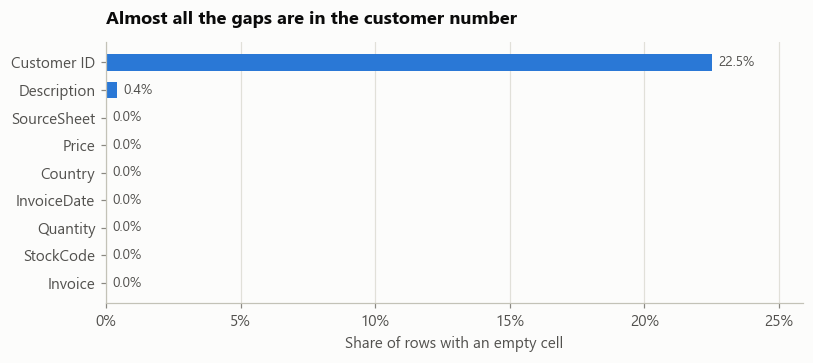

In [6]:
pct = (raw.isna().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
bars = ax.barh(pct.index, pct.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in pct.values], padding=4, color=INK_SOFT, fontsize=9)
ax.set_title("Almost all the gaps are in the customer number")
ax.set_xlabel("Share of rows with an empty cell")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xlim(0, pct.max() * 1.15)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 2.6 Duplicate rows

A duplicate is a row that is an exact copy of another row in every column. These can be genuine (the same item scanned twice on one order) or a recording glitch. We count them here and decide what to do in Step 3.

In [7]:
original_columns = [c for c in raw.columns if c != "SourceSheet"]
dupes = raw.duplicated(subset=original_columns, keep="first")
print(f"Exact duplicate rows: {dupes.sum():,} ({dupes.mean():.2%} of all rows)")

# Show one example so we can see what a duplicate looks like
example = raw[raw.duplicated(subset=original_columns, keep=False)].sort_values(original_columns).head(4)
display(example[original_columns].astype({"Customer ID": "Int64"}))

Exact duplicate rows: 11,812 (1.13% of all rows)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom


## 2.7 Rows that are not ordinary sales

Not every row is a customer buying a product. The dataset documentation says an invoice number starting with **"C" is a cancellation**. We also check for negative quantities, prices of zero or less, and product codes that are really fees or adjustments (postage, bank charges, manual corrections).

In [8]:
first_letter = raw["Invoice"].str[0]
invoice_type = np.select(
    [first_letter == "C", first_letter.str.isalpha()],
    ["Cancellation (starts with C)", "Other letter prefix"],
    default="Normal sale",
)
display(
    pd.DataFrame({"Rows": pd.Series(invoice_type).value_counts()})
      .assign(**{"% of rows": lambda d: d["Rows"] / len(raw) * 100})
)

# Normal product codes are 5 digits, sometimes followed by letters (for colour or size)
is_product_code = raw["StockCode"].str.fullmatch(r"\d{5}[A-Za-z]*")

checks = pd.Series({
    "Quantity below zero (returns or corrections)": (raw["Quantity"] < 0).sum(),
    "Quantity below zero on a NON-cancelled invoice": ((raw["Quantity"] < 0) & (first_letter != "C")).sum(),
    "Price equal to zero": (raw["Price"] == 0).sum(),
    "Price below zero": (raw["Price"] < 0).sum(),
    "Product code that is not a normal product": (~is_product_code).sum(),
}, name="Rows").to_frame()
checks["% of rows"] = checks["Rows"] / len(raw) * 100
display(checks)

,Rows,% of rows
Normal sale,1025677,98.17
Cancellation (starts with C),19165,1.83
Other letter prefix,6,0.00


,Rows,% of rows
Quantity below zero (returns or corrections),22557,2.16
Quantity below zero on a NON-cancelled invoice,3393,0.32
Price equal to zero,6024,0.58
Price below zero,5,0.00
Product code that is not a normal product,5993,0.57


In [9]:
# The most common codes that do not look like a normal product
special = (
    raw[~is_product_code]
    .groupby("StockCode")
    .agg(Rows=("StockCode", "size"),
         Description=("Description", lambda s: s.dropna().mode().iat[0] if s.notna().any() else "(blank)"),
         Total_value=("Price", lambda s: (s * raw.loc[s.index, "Quantity"]).sum()))
    .sort_values("Rows", ascending=False)
    .rename(columns={"Total_value": "Total value (£)"})
)
print(f"{len(special)} different special codes. The 12 most common:")
display(special.head(12))

63 different special codes. The 12 most common:


,Rows,Description,Total value (£)
StockCode,,,
POST,2086,POSTAGE,"110,430.41"
DOT,1425,DOTCOM POSTAGE,"309,844.10"
M,1398,Manual,"-82,950.62"
C2,277,CARRIAGE,"13,136.00"
D,173,Discount,"-12,879.63"
S,102,SAMPLES,"-6,000.85"
BANK CHARGES,100,Bank Charges,"-35,482.25"
ADJUST,67,Adjustment by john on 26/01/2010 16,"6,835.24"
AMAZONFEE,36,AMAZON FEE,"-221,520.50"


## 2.8 Outliers (extreme values)

An outlier is a value far away from the rest, such as one order for 80,000 units when a typical order line is 3 units. Outliers matter a lot for clustering because the methods work by measuring distances, and one giant value can drag everything out of shape.

We use a common rule of thumb called the **IQR rule**: take the middle half of the values, and flag anything that sits more than 1.5 times that range above or below it.

In [10]:
line_value = (raw["Quantity"] * raw["Price"]).rename("Line value (Quantity x Price)")
numbers = pd.concat([raw["Quantity"], raw["Price"], line_value], axis=1)

summary = numbers.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
summary = summary.rename(columns={"count": "rows", "mean": "average", "std": "spread (std)",
                                  "min": "smallest", "50%": "middle (median)", "max": "largest"})
display(summary)

def iqr_outliers(values):
    q1, q3 = values.quantile([0.25, 0.75])
    spread = q3 - q1
    low, high = q1 - 1.5 * spread, q3 + 1.5 * spread
    flagged = (values < low) | (values > high)
    return pd.Series({"Normal range from": low, "Normal range to": high,
                      "Rows outside": flagged.sum(), "% of rows": flagged.mean() * 100})

display(numbers.apply(iqr_outliers).T.astype({"Rows outside": int}))

,rows,average,spread (std),smallest,1%,25%,middle (median),75%,99%,largest
Quantity,"1,044,848.00",9.99,174.22,"-80,995.00",-3.00,1.00,3.00,10.00,100.00,"80,995.00"
Price,"1,044,848.00",4.59,121.70,"-53,594.36",0.21,1.25,2.10,4.13,18.00,"38,970.00"
Line value (Quantity x Price),"1,044,848.00",18.10,294.02,"-168,469.60",-7.95,3.75,9.90,17.70,180.00,"168,469.60"


,Normal range from,Normal range to,Rows outside,% of rows
Quantity,-12.50,23.50,114673,10.98
Price,-3.07,8.45,82978,7.94
Line value (Quantity x Price),-17.18,38.63,89105,8.53


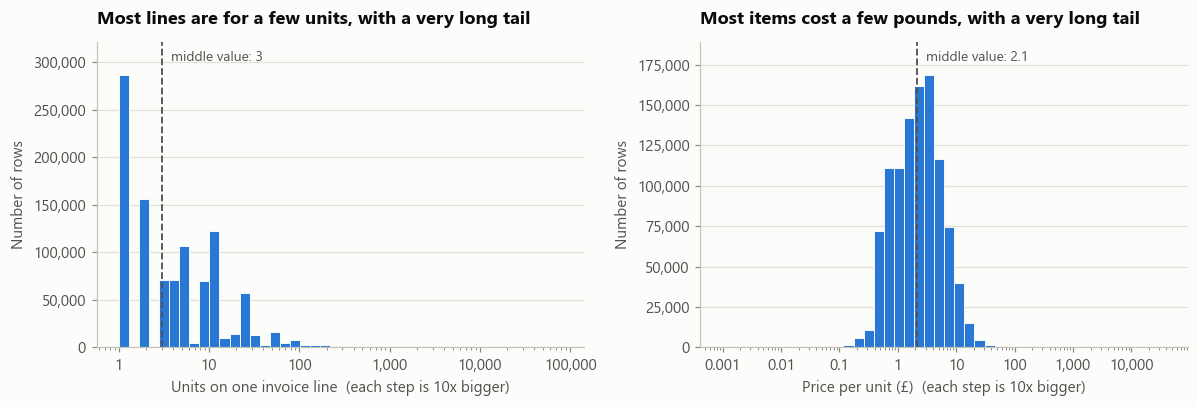

In [11]:
# How quantity and price are spread out. Only values above zero are drawn, and the
# horizontal axis grows in steps of x10 because the values are extremely lopsided.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
panels = [("Quantity", "Units on one invoice line", "Most lines are for a few units"),
          ("Price", "Price per unit (£)", "Most items cost a few pounds")]
for ax, (col, xlabel, title) in zip(axes, panels):
    positive = raw.loc[raw[col] > 0, col]
    bins = np.logspace(np.log10(positive.min()), np.log10(positive.max()), 45)
    ax.hist(positive, bins=bins, color=BLUE, edgecolor="#fcfcfb", linewidth=0.6)
    ax.axvline(positive.median(), color=INK_SOFT, linewidth=1.2, linestyle="--")
    ax.annotate(f"middle value: {positive.median():,.2f}".rstrip("0").rstrip("."),
                xy=(positive.median(), 1), xycoords=("data", "axes fraction"),
                xytext=(6, -12), textcoords="offset points", color=INK_SOFT, fontsize=9)
    ax.set_xscale("log")
    ax.margins(y=0.12)
    ax.set_title(title + ", with a very long tail")
    ax.set_xlabel(xlabel + "  (each step is 10x bigger)")
    ax.set_ylabel("Number of rows")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:g}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 2.9 Where do the customers come from?

,Customers,Rows,% of customers,% of rows
Country,,,,
United Kingdom,5410,959983,91.05,91.88
Germany,107,17363,1.80,1.66
France,95,14059,1.60,1.35
Spain,41,3766,0.69,0.36
Belgium,29,3111,0.49,0.30
Portugal,24,2540,0.40,0.24
Netherlands,23,5138,0.39,0.49
Switzerland,22,3183,0.37,0.30
Sweden,19,1364,0.32,0.13


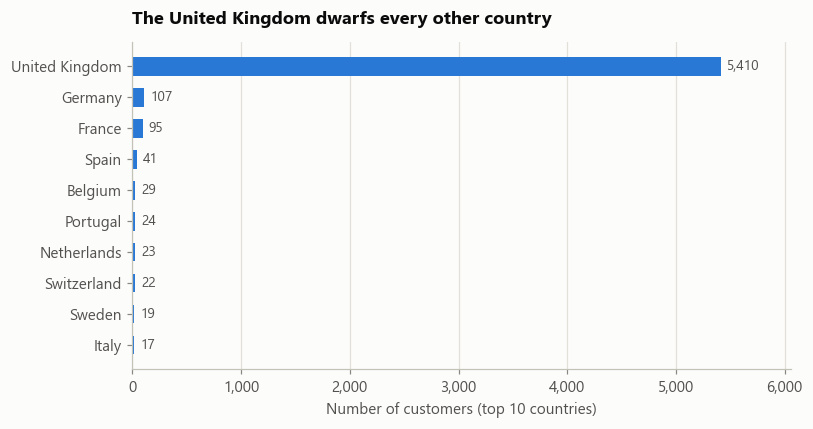

In [12]:
by_country = (
    raw.groupby("Country")
       .agg(Customers=("Customer ID", "nunique"), Rows=("Invoice", "size"))
       .sort_values("Customers", ascending=False)
)
by_country["% of customers"] = by_country["Customers"] / raw["Customer ID"].nunique() * 100
by_country["% of rows"] = by_country["Rows"] / len(raw) * 100
display(by_country.head(10))

top = by_country.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.barh(top.index, top["Customers"], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:,}" for v in top["Customers"]], padding=4, color=INK_SOFT, fontsize=9)
ax.set_title("The United Kingdom dwarfs every other country")
ax.set_xlabel("Number of customers (top 10 countries)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlim(0, top["Customers"].max() * 1.12)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 2.10 Data dictionary

A data dictionary is a plain-language guide to every column: what it means, what type of value it holds, what unit it is in, and what values are allowed. The meanings come from the UCI dataset documentation; the numbers on the right are measured from our file.

In [13]:
dictionary = pd.DataFrame([
    ("Invoice", "Invoice (order) number. All lines of one order share it.", "Text label", "none",
     "6 digits. Starts with 'C' if the order was cancelled."),
    ("StockCode", "Product code. Each different product has its own.", "Text label", "none",
     "5 digits, sometimes plus letters. A few special codes for fees (e.g. POST, M, D)."),
    ("Description", "Product name.", "Free text", "none", "Any text."),
    ("Quantity", "How many units of the product are on this invoice line.", "Whole number", "units",
     "Above zero for a sale. Below zero for a return or cancellation."),
    ("InvoiceDate", "Date and time the invoice was created.", "Date and time", "day and time (UK)",
     "1 Dec 2009 to 9 Dec 2011."),
    ("Price", "Price of ONE unit of the product.", "Decimal number", "pounds sterling (£)",
     "Above zero for a normal sale."),
    ("Customer ID", "Customer number. Each customer has their own.", "Label, stored as a number", "none",
     "5 digits. Empty when the buyer was not identified."),
    ("Country", "Country where the customer lives.", "Category", "none", "Country name."),
    ("SourceSheet", "Which Excel sheet the row came from (added by us).", "Category", "none",
     "'Year 2009-2010' or 'Year 2010-2011'."),
], columns=["Column", "What it means", "Type", "Unit", "Allowed values"]).set_index("Column")

dictionary["Different values"] = raw.nunique()
dictionary["% empty"] = (raw.isna().mean() * 100).round(2)
dictionary["Seen in our file"] = pd.Series({
    "Invoice": f"{raw['Invoice'].nunique():,} invoices",
    "StockCode": f"{raw['StockCode'].nunique():,} codes",
    "Description": "e.g. " + raw["Description"].dropna().iat[0].strip(),
    "Quantity": f"{raw['Quantity'].min():,} to {raw['Quantity'].max():,}",
    "InvoiceDate": f"{raw['InvoiceDate'].min():%d %b %Y} to {raw['InvoiceDate'].max():%d %b %Y}",
    "Price": f"{raw['Price'].min():,.2f} to {raw['Price'].max():,.2f}",
    "Customer ID": f"{raw['Customer ID'].min():.0f} to {raw['Customer ID'].max():.0f}",
    "Country": f"{raw['Country'].nunique()} countries",
    "SourceSheet": ", ".join(raw["SourceSheet"].unique()),
})

with pd.option_context("display.max_colwidth", None):
    display(dictionary)

,What it means,Type,Unit,Allowed values,Different values,% empty,Seen in our file
Column,,,,,,,
Invoice,Invoice (order) number. All lines of one order share it.,Text label,none,6 digits. Starts with 'C' if the order was cancelled.,53628,0.00,"53,628 invoices"
StockCode,Product code. Each different product has its own.,Text label,none,"5 digits, sometimes plus letters. A few special codes for fees (e.g. POST, M, D).",5305,0.00,"5,305 codes"
Description,Product name.,Free text,none,Any text.,5698,0.41,e.g. 15CM CHRISTMAS GLASS BALL 20 LIGHTS
Quantity,How many units of the product are on this invoice line.,Whole number,units,Above zero for a sale. Below zero for a return or cancellation.,1057,0.00,"-80,995 to 80,995"
InvoiceDate,Date and time the invoice was created.,Date and time,day and time (UK),1 Dec 2009 to 9 Dec 2011.,47635,0.00,01 Dec 2009 to 09 Dec 2011
Price,Price of ONE unit of the product.,Decimal number,pounds sterling (£),Above zero for a normal sale.,2807,0.00,"-53,594.36 to 38,970.00"
Customer ID,Customer number. Each customer has their own.,"Label, stored as a number",none,5 digits. Empty when the buyer was not identified.,5942,22.52,12346 to 18287
Country,Country where the customer lives.,Category,none,Country name.,43,0.00,43 countries
SourceSheet,Which Excel sheet the row came from (added by us).,Category,none,'Year 2009-2010' or 'Year 2010-2011'.,2,0.00,"Year 2009-2010, Year 2010-2011"


## 2.11 What we found in Step 2

**The dataset at a glance:** about 1.04 million product lines from 53,628 invoices, covering 1 December 2009 to 9 December 2011, with 5,942 identified customers in 43 countries.

| What we noticed | How big is it | What it means for Step 3 |
|---|---|---|
| **Missing customer numbers** | 22.5% of rows | These rows cannot be linked to a customer, so they cannot be used to describe customer behaviour. |
| **Missing product descriptions** | 0.4% of rows | Minor. We do not need the description to build customer features. |
| **Exact duplicate rows** | 11,812 rows (1.1%) | Need a decision: remove or keep. |
| **Cancelled invoices** | 19,165 rows (1.8%) | Not sales. Should not count as spending, but they are useful as a "how often does this customer return things" signal. |
| **Zero or negative prices** | 6,024 rows at zero, 5 below zero | Free items, write-offs and accounting corrections. Not real purchases. |
| **Fee and adjustment codes** (postage, bank charges, manual corrections) | 5,993 rows (0.6%) | Not products. They would distort spending figures. |
| **Extreme values** | Quantities from -80,995 to 80,995. About 8% to 11% of rows fall outside the "normal range" | Typical line is 3 units at £2.10, but a few lines are enormous. Must be tamed before clustering, because clustering is sensitive to extremes. |
| **One country dominates** | 91% of customers are in the United Kingdom | Country will not be a useful way to tell customers apart, but it matters for the fairness check in Step 5. |
| **Customer ID stored as a decimal number** | All rows | Cosmetic. Will be converted to a whole-number label. |

**Deliverable for Step 2:** dataset overview (sections 2.3 to 2.9) + data dictionary (section 2.10).

---
# Step 3: Data Preprocessing, Applied EDA and Feature Engineering

**What we are doing:** turning a million messy invoice lines into one tidy row per customer that describes how that customer shops. This is the most important step, because a clustering method can only be as good as the information we feed it.

The path we follow:

1. **Clean** the invoice lines (remove what cannot be used).
2. **Build customer features**, with RFM at the centre.
3. **Tame the extreme values** and put every feature on the same scale.
4. **Explore** the features: how they are spread and how they relate to each other.
5. **Choose** which features to keep.
6. **Check** whether the data naturally forms groups at all.
7. **Squash** the features down to two dimensions so we can draw the customers on a flat map.

## 3.1 Cleaning the invoice lines

These are the rules agreed after Step 2, applied in order:

| # | Rule | Why |
|---|---|---|
| 1 | Remove rows with no customer number | They cannot be linked to any customer. |
| 2 | Remove exact duplicate rows | Most likely the same line recorded twice. |
| 3 | Remove fee and adjustment codes (postage, bank charges, manual corrections) | They are not products and would distort spending. |
| 4 | Set cancellations aside in their own table | They are not spending, but they tell us how often a customer returns things. |
| 5 | Keep as sales only rows with a quantity above zero and a price above zero | Anything else is a correction or a free item. |

In [14]:
cleaning_log = []
def note(step, table):
    cleaning_log.append({"Step": step, "Rows left": len(table)})

df = raw.copy()
note("Starting point", df)

# 1. Rows with no customer number
df = df.dropna(subset=["Customer ID"])
df["Customer ID"] = df["Customer ID"].astype(int)     # 13085.0 becomes 13085
note("1. Remove rows with no customer number", df)

# 2. Exact duplicates
df = df.drop_duplicates(subset=original_columns)
note("2. Remove exact duplicate rows", df)

# 3. Fee and adjustment codes (anything that is not 5 digits plus optional letters)
df = df[df["StockCode"].str.fullmatch(r"\d{5}[A-Za-z]*")]
note("3. Remove fee and adjustment codes", df)

# Value of each line in pounds
df["LineValue"] = df["Quantity"] * df["Price"]

# 4. Cancellations go into their own table
is_cancellation = df["Invoice"].str.startswith("C")
returns = df[is_cancellation & (df["Quantity"] < 0) & (df["Price"] > 0)].copy()

# 5. Sales: not cancelled, quantity above zero, price above zero
sales = df[~is_cancellation & (df["Quantity"] > 0) & (df["Price"] > 0)].copy()
note("4-5. Keep genuine sales only", sales)

cleaning_log = pd.DataFrame(cleaning_log).set_index("Step")
cleaning_log["Rows removed"] = -cleaning_log["Rows left"].diff().fillna(0).astype(int)
cleaning_log["% of original kept"] = cleaning_log["Rows left"] / len(raw) * 100
display(cleaning_log)

print(f"Sales table:   {len(sales):,} rows, {sales['Invoice'].nunique():,} invoices, "
      f"{sales['Customer ID'].nunique():,} customers")
print(f"Returns table: {len(returns):,} rows, {returns['Invoice'].nunique():,} cancelled invoices, "
      f"{returns['Customer ID'].nunique():,} customers")
print(f"Empty cells left in the sales table: {int(sales.isna().sum().sum())}")

,Rows left,Rows removed,% of original kept
Step,,,
Starting point,1044848,0,100.00
1. Remove rows with no customer number,809561,235287,77.48
2. Remove exact duplicate rows,797885,11676,76.36
3. Remove fee and adjustment codes,794223,3662,76.01
4-5. Keep genuine sales only,776577,17646,74.32


Sales table:   776,577 rows, 36,594 invoices, 5,852 customers
Returns table: 17,586 rows, 7,282 cancelled invoices, 2,444 customers
Empty cells left in the sales table: 0


**What we found:** about three quarters of the original rows survive (776,577 sales lines from 36,594 invoices). The biggest loss by far is the 235,287 rows with no customer number. We end up with **5,852 customers**; the other 90 customer numbers in the raw file only ever appeared on cancellations or fee lines, so there is no buying behaviour to describe.

## 3.2 A quick look at the cleaned sales

Before building customer features, two simple questions about the business as a whole: **when** does the shop sell, and **how evenly** is the revenue spread across customers?

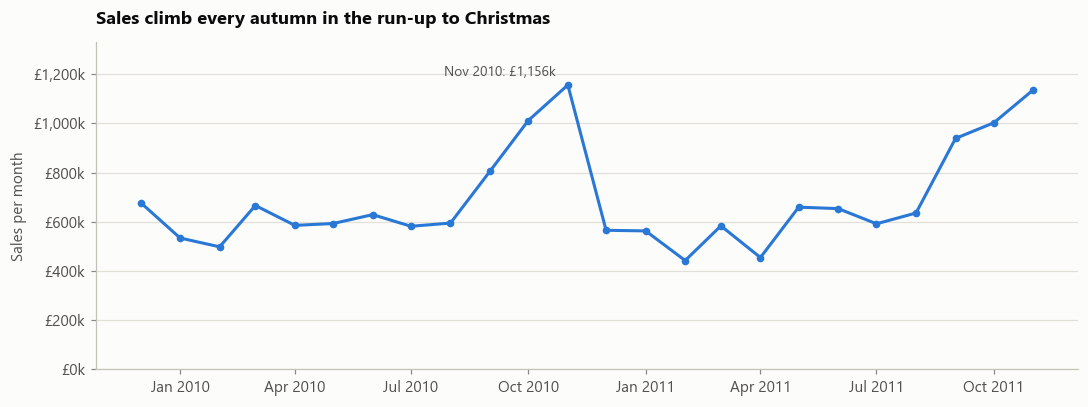

The top 20% of customers bring in 77% of all sales.


The top 1% of customers (58 people) bring in 32% of all sales.


In [15]:
import matplotlib.dates as mdates

monthly = sales.set_index("InvoiceDate")["LineValue"].resample("MS").sum()
monthly = monthly.iloc[:-1]      # the last month (Dec 2011) only has 9 days, so we leave it out

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(monthly.index, monthly.values, color=BLUE, linewidth=2, marker="o", markersize=4)
peak = monthly.idxmax()
ax.annotate(f"{peak:%b %Y}: £{monthly.max()/1000:,.0f}k", xy=(peak, monthly.max()),
            xytext=(-8, 6), textcoords="offset points", ha="right", color=INK_SOFT, fontsize=9)
ax.set_title("Sales climb every autumn in the run-up to Christmas")
ax.set_ylabel("Sales per month")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"£{v/1000:,.0f}k"))
ax.set_ylim(0, monthly.max() * 1.15)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

# How concentrated is the revenue?
spend = sales.groupby("Customer ID")["LineValue"].sum().sort_values(ascending=False)
top20 = spend.head(int(len(spend) * 0.20)).sum() / spend.sum()
top1 = spend.head(int(len(spend) * 0.01)).sum() / spend.sum()
print(f"The top 20% of customers bring in {top20:.0%} of all sales.")
print(f"The top 1% of customers ({int(len(spend) * 0.01)} people) bring in {top1:.0%} of all sales.")

**What we found:**

- **Strong Christmas season.** Most months bring in roughly £450k to £650k, then sales climb from September and pass £1.1 million in November, in both years.
- **A small group carries the business.** The top 20% of customers bring in 77% of sales, and the top 1% (just 58 customers) bring in 32%. Finding and looking after that small group is where most of the money is.

## 3.3 Building the customer features

Now we squeeze each customer's invoice lines into a single row. The heart of it is **RFM**, a long-standing marketing recipe that describes a customer with three numbers:

| Letter | Feature | Plain meaning |
|---|---|---|
| **R** | Recency | How many days since their last purchase? (lower is better) |
| **F** | Frequency | How many separate orders have they placed? |
| **M** | Monetary | How much have they spent in total? |

RFM alone misses some things, so we add a few extras drawn from knowing how a shop works:

| Feature | Plain meaning | Why it could matter |
|---|---|---|
| AvgOrderValue | Typical value of one order | Separates a few big orders from many small ones |
| TotalUnits | Total number of items bought | Wholesalers buy in bulk |
| UniqueProducts | How many different products they have tried | Shows how widely they shop the catalogue |
| ProductsPerOrder | Different products in a typical order | Small top-ups versus big baskets |
| AvgUnitPrice | Typical price paid per item | Cheap bulk items versus pricier gifts |
| Tenure | Days since their very first purchase | New customers versus long-standing ones |
| ReturnRate | Value returned as a share of value bought | High returners cost money to serve |

"Today" for the purpose of counting days is set to the day after the last transaction in the data.

In [16]:
today = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print(f"Reference date used as 'today': {today:%d %b %Y}")

per_customer = sales.groupby("Customer ID").agg(
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("LineValue", "sum"),
    TotalUnits=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    Lines=("Invoice", "size"),
)

customers = pd.DataFrame(index=per_customer.index)
customers["Recency"] = (today - per_customer["LastPurchase"]).dt.days
customers["Frequency"] = per_customer["Frequency"]
customers["Monetary"] = per_customer["Monetary"]
customers["AvgOrderValue"] = per_customer["Monetary"] / per_customer["Frequency"]
customers["TotalUnits"] = per_customer["TotalUnits"]
customers["UniqueProducts"] = per_customer["UniqueProducts"]
customers["ProductsPerOrder"] = per_customer["Lines"] / per_customer["Frequency"]
customers["AvgUnitPrice"] = per_customer["Monetary"] / per_customer["TotalUnits"]
customers["Tenure"] = (today - per_customer["FirstPurchase"]).dt.days

# Return rate: pounds returned divided by pounds bought, kept between 0 and 1
returned_value = (-returns["LineValue"]).groupby(returns["Customer ID"]).sum()
customers["ReturnRate"] = (returned_value.reindex(customers.index).fillna(0) / customers["Monetary"]).clip(0, 1)

CANDIDATES = list(customers.columns)
print(f"{len(customers):,} customers, {len(CANDIDATES)} candidate features")
display(customers.head())
display(customers.describe().T[["mean", "min", "50%", "max"]]
        .rename(columns={"mean": "average", "min": "smallest", "50%": "middle (median)", "max": "largest"}))

Reference date used as 'today': 10 Dec 2011
5,852 customers, 10 candidate features


,Recency,Frequency,Monetary,AvgOrderValue,TotalUnits,UniqueProducts,ProductsPerOrder,AvgUnitPrice,Tenure,ReturnRate
Customer ID,,,,,,,,,,
12346,325,3,"77,352.96","25,784.32",74239,25,8.33,1.04,647,1.00
12347,2,8,"4,921.53",615.19,2967,126,27.75,1.66,404,0.00
12348,75,5,"1,658.40",331.68,2704,24,9.20,0.61,438,0.00
12349,18,3,"3,678.69","1,226.23",1621,137,57.33,2.27,589,0.01
12350,310,1,294.40,294.40,196,16,16.00,1.50,310,0.00


,average,smallest,middle (median),largest
Recency,199.73,0.00,95.00,738.00
Frequency,6.25,1.00,3.00,373.00
Monetary,"2,916.71",2.95,856.02,"580,987.04"
AvgOrderValue,384.40,2.95,277.87,"84,236.25"
TotalUnits,"1,794.04",1.00,484.50,"367,072.00"
UniqueProducts,82.19,1.00,45.00,"2,546.00"
ProductsPerOrder,21.60,1.00,17.09,299.71
AvgUnitPrice,2.22,0.12,1.80,329.89
Tenure,473.54,0.00,529.00,738.00
ReturnRate,0.02,0.00,0.00,1.00


**What we found:** the typical (middle) customer has placed 3 orders, spent £856 in total, and last ordered 95 days ago. The averages are much higher than the middle values (average spend is £2,917), which is the first sign that a few very large customers are stretching the numbers.

Customer 12346 in the table above is a good example of why the return rate is useful: they "spent" £77,353, but returned practically all of it. Without the return rate they would look like a star customer.

### Encoding: turning country into a number

Clustering methods only understand numbers, so a text column such as *Country* has to be converted ("encoded"). With 91% of customers in one country, the simplest honest encoding is a yes/no flag: **is this customer in the UK?** (1 = yes, 0 = no).

**Important choice:** we record this flag but we do **not** feed it into the clustering. We want groups based on how people shop, not where they live. Keeping country out of the model also lets us use it in Step 5 as an independent fairness check: are customers abroad being pushed into worse segments?

In [17]:
# A handful of customers appear under more than one country, so we take their most common one
home_country = sales.groupby("Customer ID")["Country"].agg(lambda s: s.mode().iat[0])
customers["Country"] = home_country
customers["IsUK"] = (customers["Country"] == "United Kingdom").astype(int)

display(customers["IsUK"].map({1: "UK", 0: "Outside UK"}).value_counts()
        .rename_axis("Location").to_frame("Customers")
        .assign(**{"% of customers": lambda d: d["Customers"] / len(customers) * 100}))

,Customers,% of customers
Location,,
UK,5334,91.15
Outside UK,518,8.85


### Binning: classic RFM scores

Binning means sorting a number into buckets, the way exam marks become grades. The traditional RFM approach gives each customer a score from **1 (worst) to 5 (best)** on each of R, F and M, by splitting customers into five equal-sized buckets.

We build these scores for two reasons: they are easy for a business reader to understand, and they give us a simple hand-made segmentation to compare our clusters against later. They are **not** used as inputs to the clustering, because they are just a rougher copy of information the model already has.

In [18]:
# Lower recency is better, so the labels run backwards for R
customers["R_Score"] = pd.qcut(customers["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
# Many customers share the same frequency, so we rank first to get equal-sized buckets
customers["F_Score"] = pd.qcut(customers["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
customers["M_Score"] = pd.qcut(customers["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
customers["RFM_Total"] = customers[["R_Score", "F_Score", "M_Score"]].sum(axis=1)

# What does each spending grade look like?
display(customers.groupby("M_Score").agg(
    Customers=("Monetary", "size"),
    Typical_spend=("Monetary", "median"),
    Typical_orders=("Frequency", "median"),
    Typical_days_since_last_order=("Recency", "median"),
).rename(columns=lambda c: c.replace("_", " ")))

,Customers,Typical spend,Typical orders,Typical days since last order
M_Score,,,,
1,1171,161.35,1.00,385.00
2,1170,404.35,2.00,260.50
3,1170,856.02,3.00,107.50
4,1170,"1,793.77",6.00,60.00
5,1171,"5,394.07",13.00,23.00


## 3.4 Outliers at the customer level

Step 2 showed that a few invoice lines are enormous. The same is true of customers: most spend a few hundred pounds, a few spend hundreds of thousands. The charts below show how lopsided each feature is.

**Skewness** is a single number for lopsidedness. Zero means balanced, like heights of adults. Above 1 means a long tail to the right, like incomes.

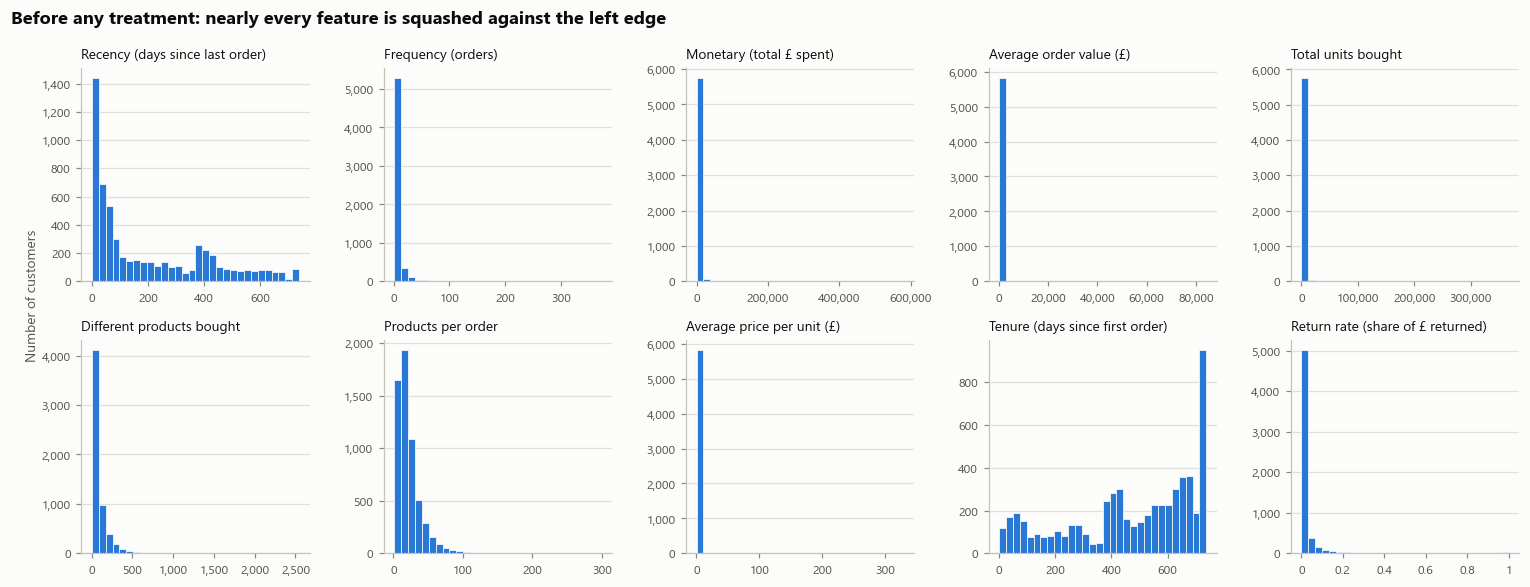

In [19]:
NICE = {
    "Recency": "Recency (days since last order)", "Frequency": "Frequency (orders)",
    "Monetary": "Monetary (total £ spent)", "AvgOrderValue": "Average order value (£)",
    "TotalUnits": "Total units bought", "UniqueProducts": "Different products bought",
    "ProductsPerOrder": "Products per order", "AvgUnitPrice": "Average price per unit (£)",
    "Tenure": "Tenure (days since first order)", "ReturnRate": "Return rate (share of £ returned)",
}

def plot_distributions(table, title):
    cols = list(table.columns)
    ncol = 5
    nrow = int(np.ceil(len(cols) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(14, 2.7 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        ax.hist(table[col], bins=30, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
        ax.set_title(NICE.get(col, col), fontsize=9, fontweight="normal", pad=6)
        ax.tick_params(labelsize=8)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}" if abs(v) >= 10 else f"{v:g}"))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.grid(axis="x", visible=False)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=12)
    fig.supylabel("Number of customers", fontsize=9, color=INK_SOFT)
    plt.tight_layout()
    plt.show()

plot_distributions(customers[CANDIDATES], "Before any treatment: nearly every feature is squashed against the left edge")

### How we treat the extremes

We do **not** delete the extreme customers. They are real, and the biggest spenders are probably the most valuable people in the whole dataset. Instead we do two gentle things:

1. **Capping:** any value above the 99th percentile is pulled down to the 99th percentile. A customer who spent £500,000 is still recorded as a top spender, but can no longer pull the whole picture out of shape.
2. **Log transform:** for features that are still lopsided, we swap the raw number for its logarithm. In plain terms, this measures differences in *multiples* rather than in pounds, so the gap between £100 and £1,000 counts the same as the gap between £1,000 and £10,000.

,Cap (99th percentile),Customers capped,Skewness: raw,Skewness: after capping,Log applied,Skewness: final
Recency,726.00,56,0.89,0.89,no,0.89
Frequency,46.00,58,12.04,3.03,yes,0.82
Monetary,"28,631.08",59,25.33,4.11,yes,0.12
AvgOrderValue,"1,907.11",59,53.38,2.84,yes,-0.31
TotalUnits,"16,727.64",59,21.82,4.08,yes,-0.11
UniqueProducts,502.98,59,6.22,2.25,yes,-0.30
ProductsPerOrder,88.54,59,3.27,1.65,yes,-0.49
AvgUnitPrice,7.20,59,42.65,2.25,yes,0.73
Tenure,738.00,0,-0.62,-0.62,no,-0.62
ReturnRate,0.39,59,8.10,4.75,yes,4.40


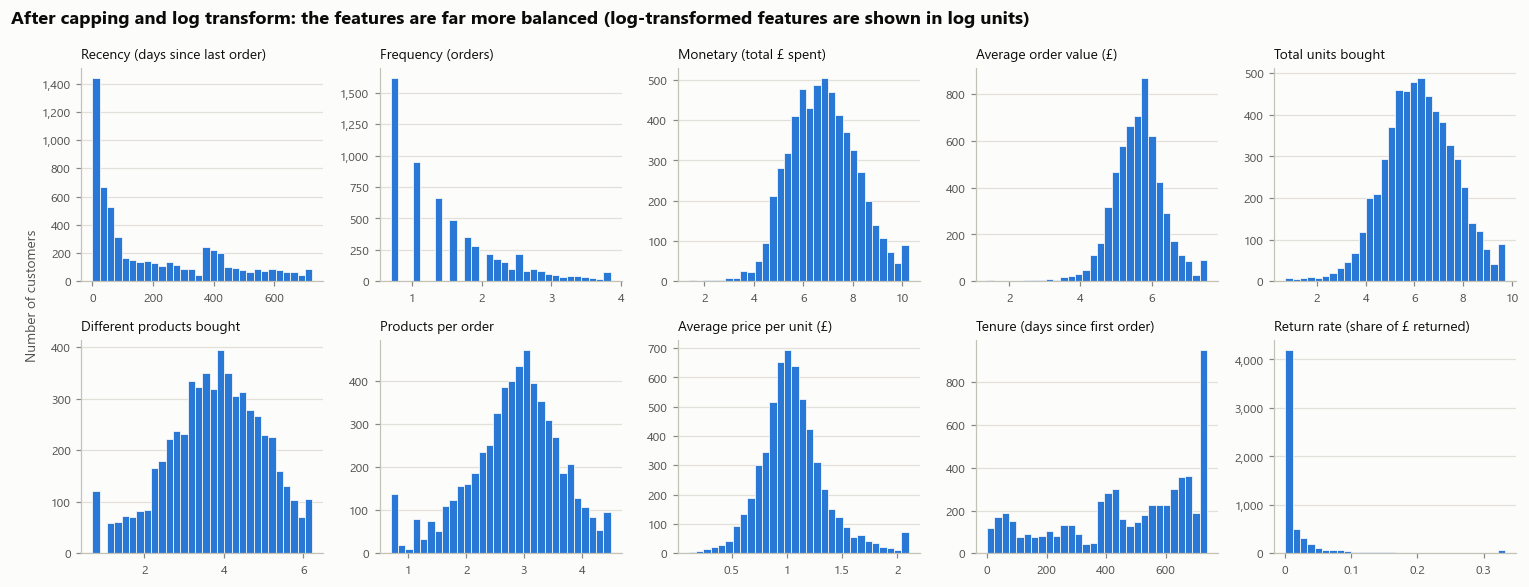

In [20]:
# 1. Capping at the 99th percentile
caps = customers[CANDIDATES].quantile(0.99)
capped = customers[CANDIDATES].clip(upper=caps, axis=1)

# 2. Log transform for features that are still strongly lopsided (skewness above 1)
skew_after_cap = capped.skew()
LOG_FEATURES = [c for c in CANDIDATES if skew_after_cap[c] > 1]
transformed = capped.copy()
transformed[LOG_FEATURES] = np.log1p(transformed[LOG_FEATURES])     # log1p copes with zeros

treatment = pd.DataFrame({
    "Cap (99th percentile)": caps,
    "Customers capped": (customers[CANDIDATES] > caps).sum(),
    "Skewness: raw": customers[CANDIDATES].skew(),
    "Skewness: after capping": skew_after_cap,
    "Log applied": ["yes" if c in LOG_FEATURES else "no" for c in CANDIDATES],
    "Skewness: final": transformed.skew(),
})
display(treatment)

plot_distributions(transformed, "After capping and log transform: the features are far more balanced (log-transformed features are shown in log units)")

**What we found:** capping touched only about 59 customers per feature (the top 1%), and the log transform brought skewness down from as high as 53 to between -1 and 1 for almost every feature.

Two things to be aware of:

- **Recency and Tenure were left alone** because they were not badly lopsided to begin with. Both show a bump around 380 to 400 days, which is last year's Christmas shoppers.
- **Return rate is still lopsided**, and no transform can fix that: 59% of customers have never returned anything, so they all sit at exactly zero. It is kept as it is.

## 3.5 How the features relate to each other

If two features always move together, they are telling the same story twice. That matters for clustering: a story told twice gets counted twice, which quietly gives it double the influence.

The grid below shows how strongly each pair of features moves together, on a scale from **-1** (one goes up as the other goes down) through **0** (no link) to **+1** (they rise and fall together). We use the *Spearman* version, which compares rankings and is not thrown off by extreme values.

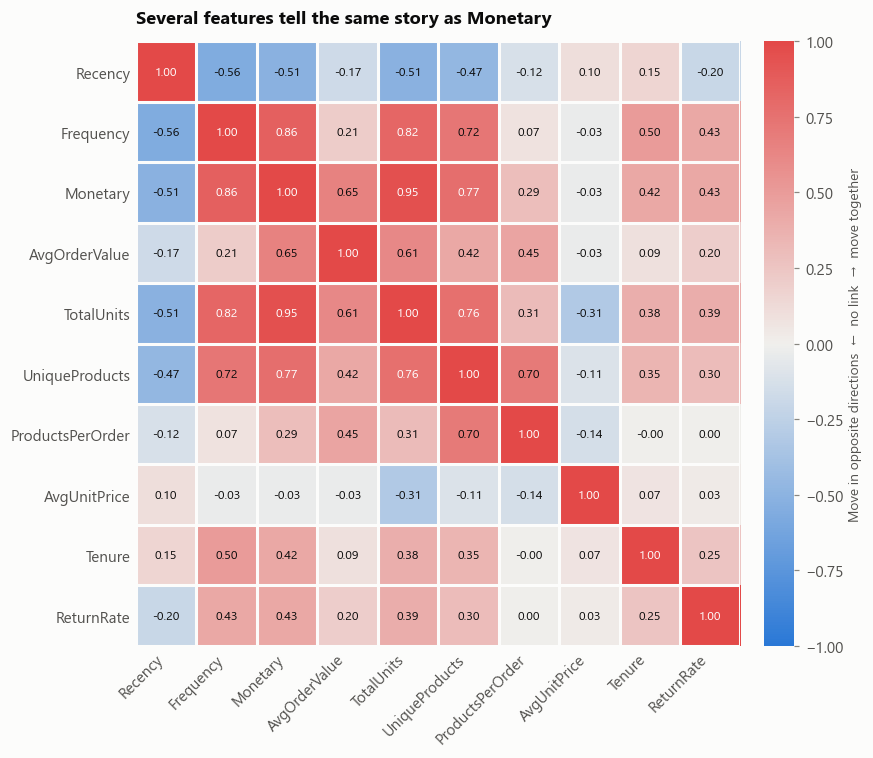

In [21]:
from matplotlib.colors import LinearSegmentedColormap

corr = transformed.corr(method="spearman")
diverging = LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(8.5, 7))
image = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iat[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.75 else INK)
ax.set_xticks(np.arange(-0.5, len(corr)), minor=True)
ax.set_yticks(np.arange(-0.5, len(corr)), minor=True)
ax.grid(False)
ax.grid(which="minor", color="#fcfcfb", linewidth=2)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
bar = fig.colorbar(image, ax=ax, fraction=0.04, pad=0.03)
bar.set_label("Move in opposite directions  ←  no link  →  move together", color=INK_SOFT, fontsize=9)
bar.outline.set_visible(False)
ax.set_title("Several features tell the same story as Monetary")
plt.tight_layout()
plt.show()

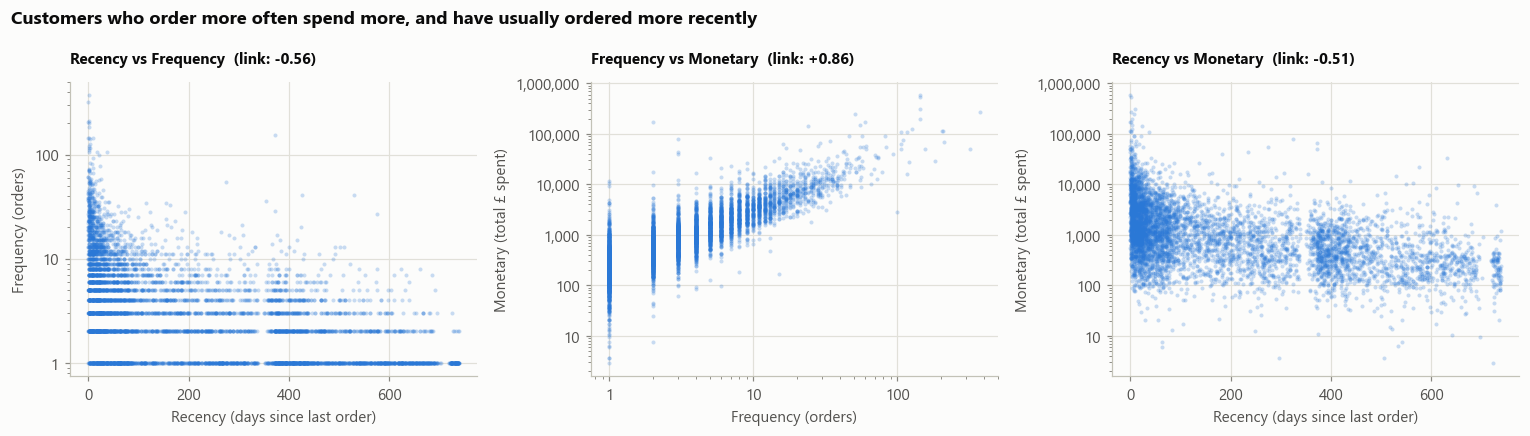

In [22]:
# The three RFM features against each other (each dot is one customer)
pairs = [("Recency", "Frequency"), ("Frequency", "Monetary"), ("Recency", "Monetary")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(customers[x], customers[y], s=7, color=BLUE, alpha=0.25, linewidths=0)
    for name, setter in ((x, ax.set_xscale), (y, ax.set_yscale)):
        if name != "Recency":
            setter("log")
    ax.set_xlabel(NICE[x]); ax.set_ylabel(NICE[y])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_title(f"{x} vs {y}  (link: {corr.loc[x, y]:+.2f})", fontsize=10)
fig.suptitle("Customers who order more often spend more, and have usually ordered more recently",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

**What we found:**

- **Monetary and TotalUnits are almost the same thing** (link of 0.95): people who spend more simply buy more units.
- **Frequency and Monetary are strongly linked** (0.86): the more often someone orders, the more they have spent.
- **Recency runs the opposite way** to Frequency and Monetary (about -0.5): customers who have not ordered for a long time tend to be the ones who ordered rarely and spent little.
- **Average unit price and return rate stand apart** from the rest, so they add information that RFM alone does not have.

## 3.6 Feature selection (filter method)

A **filter method** picks features using simple statistics, before any model is built. We apply three filters:

1. **"Does it vary?" filter.** A feature that is the same for nearly everyone cannot help tell customers apart. We drop any feature where more than 95% of customers share one value.
2. **"Is it a repeat?" filter.** When two features are linked more strongly than 0.85 (in either direction), we keep one and drop the other. Recency, Frequency and Monetary are protected, because they are the recognised core of customer segmentation and the easiest for the business to act on. Between two unprotected features, we drop the one that overlaps more with everything else.
3. **"Can it be rebuilt from the others?" filter.** Checking pairs is not enough. A feature can look fairly independent of each other feature on its own, yet be almost perfectly worked out from two of them *together*. Average order value is the obvious suspect: it is simply total spend divided by number of orders. The standard measure for this is the **VIF** (variance inflation factor). A VIF of 1 means the feature brings completely new information; above 10 is the usual warning line for "this is a repeat in disguise". We drop the worst offender, re-check, and repeat until every unprotected feature is under 10.

In [23]:
CORE = ["Recency", "Frequency", "Monetary"]
THRESHOLD = 0.85
decisions = []

def links_between(features):
    # Strength of the link between every pair of features (a feature's link with itself is set to 0)
    links = transformed[features].corr(method="spearman").abs()
    return links.where(~np.eye(len(features), dtype=bool), 0)

# Filter 1: does it vary?
most_common_share = transformed.apply(lambda s: s.round(6).value_counts(normalize=True).iloc[0])
remaining = [c for c in CANDIDATES if most_common_share[c] <= 0.95]
for c in CANDIDATES:
    if c not in remaining:
        decisions.append((c, f"dropped: {most_common_share[c]:.0%} of customers share one value"))

# Filter 2: is it a repeat?
while True:
    c_abs = links_between(remaining)
    candidates_to_drop = [(c_abs.loc[a, b], a, b) for a in remaining for b in remaining
                          if a < b and c_abs.loc[a, b] > THRESHOLD and not (a in CORE and b in CORE)]
    if not candidates_to_drop:
        break
    strength, a, b = max(candidates_to_drop)
    if a in CORE:
        drop, partner = b, a
    elif b in CORE:
        drop, partner = a, b
    else:
        drop, partner = (a, b) if c_abs[a].mean() >= c_abs[b].mean() else (b, a)
    decisions.append((drop, f"dropped: repeats {partner} (link {strength:.2f})"))
    remaining.remove(drop)

# Filter 3: can it be rebuilt from the others?
def vif(features):
    links = transformed[features].corr().values
    return pd.Series(np.diag(np.linalg.inv(links)), index=features)

vif_before = vif(remaining)
while True:
    scores = vif(remaining)
    worst = scores.drop(CORE).idxmax()
    if scores[worst] <= 10:
        break
    decisions.append((worst, f"dropped: can be rebuilt from the other features (VIF {scores[worst]:,.0f})"))
    remaining.remove(worst)

FEATURES = remaining
for c in FEATURES:
    decisions.append((c, "kept"))

selection = pd.DataFrame(decisions, columns=["Feature", "Decision"]).set_index("Feature").loc[CANDIDATES]
selection.insert(0, "Share with most common value", most_common_share.map("{:.0%}".format))
selection["VIF before filter 3"] = vif_before.round(1)
selection["VIF at the end"] = vif(FEATURES).round(1)
with pd.option_context("display.max_colwidth", None):
    display(selection.fillna("-"))

final_corr = links_between(FEATURES)
print(f"Features kept ({len(FEATURES)}): {FEATURES}")
print(f"Strongest link left among kept features: {final_corr.max().max():.2f} "
      f"({final_corr.max().idxmax()} and {final_corr.idxmax()[final_corr.max().idxmax()]})")

,Share with most common value,Decision,VIF before filter 3,VIF at the end
Feature,,,,
Recency,2%,kept,2.80,2.60
Frequency,28%,kept,52.20,5.90
Monetary,1%,kept,113.90,4.70
AvgOrderValue,1%,dropped: can be rebuilt from the other features (VIF 29),33.80,-
TotalUnits,1%,dropped: repeats Monetary (link 0.95),-,-
UniqueProducts,2%,dropped: can be rebuilt from the other features (VIF 38),38.40,-
ProductsPerOrder,2%,kept,21.20,1.40
AvgUnitPrice,1%,kept,1.10,1.00
Tenure,2%,kept,2.60,2.50


Features kept (7): ['Recency', 'Frequency', 'Monetary', 'ProductsPerOrder', 'AvgUnitPrice', 'Tenure', 'ReturnRate']
Strongest link left among kept features: 0.86 (Frequency and Monetary)


**What we found:** we go from 10 candidate features to **7**.

- **TotalUnits** was dropped by the pair filter because it repeats Monetary.
- **AvgOrderValue** and **UniqueProducts** passed the pair filter but were caught by the VIF filter: each could be almost perfectly worked out from the other features combined.
- **Frequency and Monetary are both kept even though their link (0.86) is just over our threshold.** This is a deliberate exception. They are the F and M of RFM, the business needs both to describe a segment, and once the other repeats are gone their VIF scores (5.9 and 4.7) are comfortably under the warning line of 10.
- Nothing was dropped by the "does it vary?" filter. Return rate came closest, with 59% of customers sharing the value zero.

## 3.7 Scaling: putting every feature on the same ruler

Clustering works by measuring how far apart customers are. If one feature is counted in days (0 to 700) and another is a share (0 to 1), the days would swamp everything simply because the numbers are bigger.

**Standard scaling** fixes this by re-expressing every feature as "how far above or below average is this customer?". After scaling, every feature has an average of 0 and a typical spread of 1, so each one gets an equal say.

In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(transformed[FEATURES]), index=customers.index, columns=FEATURES)

display(X.describe().T[["mean", "std", "min", "max"]]
        .rename(columns={"mean": "average", "std": "spread (std)", "min": "smallest", "max": "largest"}))

,average,spread (std),smallest,largest
Recency,-0.00,1.00,-0.96,2.53
Frequency,0.00,1.00,-1.08,2.93
Monetary,0.00,1.00,-4.01,2.56
ProductsPerOrder,0.00,1.00,-2.71,2.12
AvgUnitPrice,0.00,1.00,-3.18,3.52
Tenure,0.00,1.00,-2.12,1.18
ReturnRate,0.00,1.00,-0.38,6.46


## 3.8 Clustering tendency: are there any groups to find?

Before clustering, it is worth asking whether the data has any natural grouping at all. A clustering method will always hand back groups, even from pure noise, so we check first.

The **Hopkins statistic** answers this. It compares our customers with an imaginary set of customers scattered completely at random:

- **Around 0.5:** our data looks just like random scatter. No real groups.
- **Close to 1:** our data is much more clumped than random scatter. Groups are worth looking for.

As a sanity check we also run the same test on made-up random data, which should score about 0.5.

In [25]:
from sklearn.neighbors import NearestNeighbors

def hopkins(data, sample_size=500, seed=0):
    # Compare real nearest-neighbour distances with those of randomly scattered points
    data = np.asarray(data)
    rng = np.random.default_rng(seed)
    n, d = data.shape
    m = min(sample_size, n // 10)
    neighbours = NearestNeighbors(n_neighbors=2).fit(data)
    picked = rng.choice(n, m, replace=False)
    real_dist = neighbours.kneighbors(data[picked])[0][:, 1]             # nearest OTHER real customer
    random_points = rng.uniform(data.min(axis=0), data.max(axis=0), size=(m, d))
    random_dist = neighbours.kneighbors(random_points, n_neighbors=1)[0][:, 0]
    return random_dist.sum() / (random_dist.sum() + real_dist.sum())

ours = [hopkins(X, seed=s) for s in range(10)]
rng = np.random.default_rng(RANDOM_STATE)
noise = rng.uniform(size=X.shape)
baseline = [hopkins(noise, seed=s) for s in range(10)]

print(f"Hopkins statistic, our customers: {np.mean(ours):.3f}  (range over 10 runs: {min(ours):.3f} to {max(ours):.3f})")
print(f"Hopkins statistic, random noise:  {np.mean(baseline):.3f}  (range over 10 runs: {min(baseline):.3f} to {max(baseline):.3f})")

Hopkins statistic, our customers: 0.826  (range over 10 runs: 0.822 to 0.831)
Hopkins statistic, random noise:  0.501  (range over 10 runs: 0.497 to 0.505)


**What we found:** our customers score about **0.83**, against 0.50 for random noise. The data is clearly not random scatter, so it is worth clustering.

A word of caution: a high Hopkins score says customers are bunched up unevenly. It does not promise neat, well-separated groups. The flat maps in section 3.10 give a better feel for that.

## 3.9 Feature importance: which features do the heavy lifting?

In clustering there is no "answer" column, so we cannot ask directly which features predict it. The usual workaround has three steps:

1. Run a **quick trial clustering** (K-Means with 4 groups; the proper number of groups is chosen in Step 4).
2. Train a second model (a random forest) to **guess each customer's trial group** from the features.
3. Use **SHAP** to measure how much each feature contributed to those guesses.

SHAP works like splitting a restaurant bill fairly: for each customer it works out how much each feature pushed the model towards the group it chose. A feature with a large average SHAP value is doing a lot of the separating.

This is only a first look. The full explanation of the final model comes in Step 5.

On customers it has not seen, the forest guesses the trial group correctly 97.2% of the time.


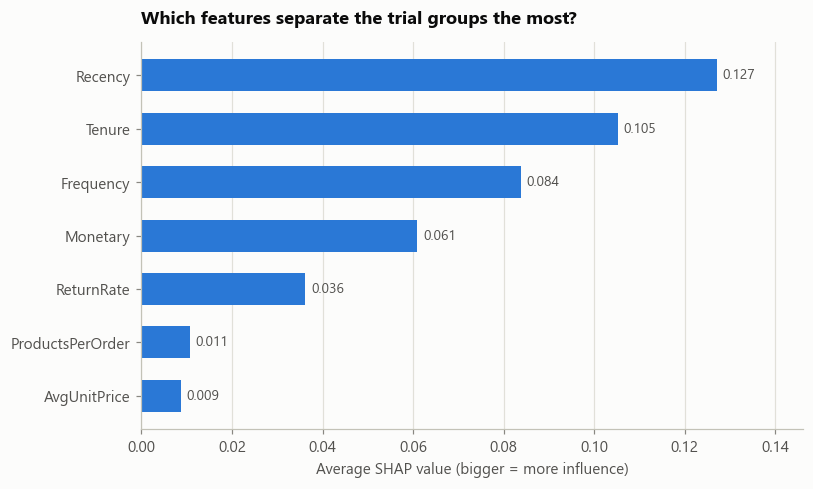

In [26]:
import shap
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

trial_groups = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
forest = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(X, trial_groups)
check = cross_val_score(forest, X, trial_groups, cv=5).mean()
print(f"On customers it has not seen, the forest guesses the trial group correctly {check:.1%} of the time.")

sample = X.sample(1000, random_state=RANDOM_STATE)
shap_values = shap.TreeExplainer(forest).shap_values(sample)
shap_values = np.stack(shap_values, axis=-1) if isinstance(shap_values, list) else np.asarray(shap_values)
importance = pd.Series(np.abs(shap_values).mean(axis=(0, 2)), index=FEATURES).sort_values()   # (customers, features, groups)

fig, ax = plt.subplots(figsize=(7.5, 0.45 * len(FEATURES) + 1.4))
bars = ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in importance.values], padding=4, color=INK_SOFT, fontsize=9)
ax.set_title("Which features separate the trial groups the most?")
ax.set_xlabel("Average SHAP value (bigger = more influence)")
ax.set_xlim(0, importance.max() * 1.15)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**What we found:** in this trial run, **Recency, Tenure, Frequency and Monetary** do most of the separating, with return rate in the middle. Products per order and average unit price contribute very little.

We keep those two weaker features for now. They describe a different side of behaviour (what kind of basket someone buys), and this trial used an arbitrary 4 groups, so it is too early to throw them out.

## 3.10 Dimensionality reduction: drawing the customers on a flat map

Each customer is now described by several numbers, which means several dimensions. We cannot draw that on a flat page, so we compress it. Three techniques are used, each with a different strength.

### PCA (Principal Component Analysis)

PCA blends the original features into a few new "summary" features, ordered so that the first one captures as much of the variety among customers as possible, the second captures the most of what is left, and so on. Think of finding the best camera angle to photograph a three-dimensional object.

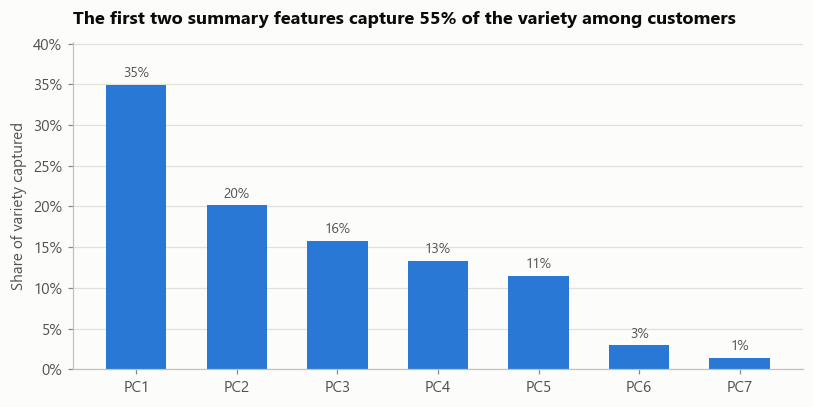

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Share captured (%),34.92,20.14,15.78,13.31,11.46,2.94,1.44
Running total (%),34.92,55.06,70.84,84.16,95.61,98.56,100.00


,PC1,PC2,PC3
Recency,-0.38,+0.46,+0.49
Frequency,+0.60,+0.14,-0.11
Monetary,+0.60,+0.03,+0.00
ProductsPerOrder,+0.21,-0.37,+0.50
AvgUnitPrice,-0.10,+0.39,-0.36
Tenure,+0.28,+0.61,+0.42
ReturnRate,+0.03,+0.33,-0.44


In [27]:
from sklearn.decomposition import PCA

pca = PCA(random_state=RANDOM_STATE).fit(X)
explained = pca.explained_variance_ratio_ * 100
cumulative = explained.cumsum()
component_names = [f"PC{i + 1}" for i in range(len(FEATURES))]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.bar(component_names, explained, color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in explained], padding=3, color=INK_SOFT, fontsize=9)
ax.set_title(f"The first two summary features capture {cumulative[1]:.0f}% of the variety among customers")
ax.set_ylabel("Share of variety captured")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylim(0, explained.max() * 1.15)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"Share captured (%)": explained, "Running total (%)": cumulative}, index=component_names).T)

# What each summary feature is made of (big numbers = that original feature matters most to it)
loadings = pd.DataFrame(pca.components_[:3].T, index=FEATURES, columns=component_names[:3])
display(loadings.style.format("{:+.2f}").background_gradient(cmap=diverging, vmin=-1, vmax=1))

**What we found:**

- **PC1 (35% of the variety) is "how much and how often".** It is made mostly of Frequency and Monetary (+0.60 each), with Recency pulling the other way. A customer with a high PC1 is a frequent, big, recent buyer.
- **PC2 (20%) is mostly about time**: how long the customer has been around (Tenure, +0.61) and how long since they last ordered (Recency, +0.46).
- **It takes 5 of the 7 summary features to capture 96% of the variety.** That means there is not much left to squeeze, which confirms the feature selection did its job. We will therefore cluster on the 7 scaled features directly, because they stay easy to explain, and use PCA only for drawing pictures.

### t-SNE and UMAP

PCA can only make straight-line blends. **t-SNE** and **UMAP** are more flexible: they arrange the customers on a flat map so that customers who are similar in the full data end up close together on the map. They are for **looking only**. Distances between far-apart blobs on these maps are not meaningful, so we never cluster on them.

In the three maps below, each dot is one customer, and darker dots are bigger spenders.

In [28]:
import warnings
from sklearn.manifold import TSNE
import umap

warnings.filterwarnings("ignore", message=".*n_jobs value.*")     # harmless notice from UMAP

maps = {
    "PCA": pca.transform(X)[:, :2],
    "t-SNE": TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE).fit_transform(X),
    "UMAP": umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(X),
}
embedding = pd.DataFrame({f"{name}_{axis}": coords[:, k] for name, coords in maps.items() for k, axis in enumerate("xy")},
                         index=customers.index)

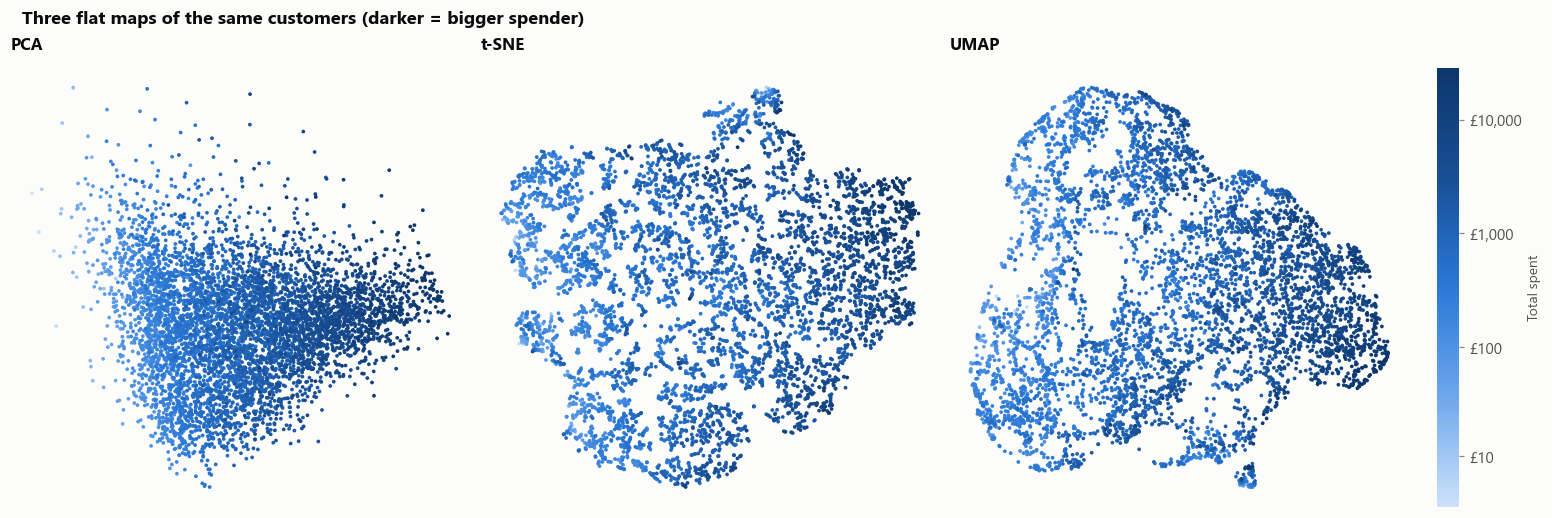

In [29]:
sequential = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
shade = transformed["Monetary"]
order = shade.argsort().values           # draw big spenders last so they are not hidden

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), constrained_layout=True)
for ax, name in zip(axes, maps):
    dots = ax.scatter(embedding[f"{name}_x"].values[order], embedding[f"{name}_y"].values[order],
                      c=shade.values[order], cmap=sequential, s=6, linewidths=0)
    ax.set_title(name, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
bar = fig.colorbar(dots, ax=axes, fraction=0.025, pad=0.02)
ticks = [t for t in [10, 100, 1_000, 10_000, 100_000] if np.log1p(t) <= shade.max()]
bar.set_ticks(np.log1p(ticks)); bar.set_ticklabels([f"£{t:,}" for t in ticks])
bar.set_label("Total spent", color=INK_SOFT, fontsize=9)
bar.outline.set_visible(False)
fig.suptitle("Three flat maps of the same customers (darker = bigger spender)", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.show()

**What we found:** all three maps agree. Customers form **one continuous cloud that shades smoothly from small spenders on one side to big spenders on the other**, rather than separate islands with empty space between them.

This is normal for shopping behaviour, and it sets honest expectations for Step 4: the segments will be more like *zones along a spectrum* than sharply separate tribes, so we should expect a moderate Silhouette Score, not a very high one. The segments can still be very useful to the business, in the same way that "small, medium and large" are useful sizes even though people's heights form a continuous range.

## 3.11 Saving the results

So that Step 4 (and anyone re-running this work) starts from exactly the same place, we save:

- the customer table, with raw features, RFM scores and country,
- the model-ready scaled features,
- the "recipe" used to prepare them: the caps, which features were log-transformed, and the scaler.

In [30]:
import json
import joblib

DATA_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

customers.to_csv(DATA_DIR / "customer_features.csv")
X.to_csv(DATA_DIR / "customer_features_scaled.csv")
joblib.dump(scaler, MODEL_DIR / "scaler.joblib")

preprocessing_config = {
    "random_state": RANDOM_STATE,
    "reference_date": f"{today:%Y-%m-%d}",
    "candidate_features": CANDIDATES,
    "selected_features": FEATURES,
    "cap_percentile": 0.99,
    "caps": {k: float(v) for k, v in caps.items()},
    "log_features": LOG_FEATURES,
    "correlation_threshold": THRESHOLD,
}
(MODEL_DIR / "preprocessing_config.json").write_text(json.dumps(preprocessing_config, indent=2))

for f in [DATA_DIR / "customer_features.csv", DATA_DIR / "customer_features_scaled.csv",
          MODEL_DIR / "scaler.joblib", MODEL_DIR / "preprocessing_config.json"]:
    print(f"Saved {f.relative_to(ROOT).as_posix()}  ({f.stat().st_size / 1024:,.0f} KB)")

Saved data/processed/customer_features.csv  (608 KB)
Saved data/processed/customer_features_scaled.csv  (828 KB)
Saved models/scaler.joblib  (1 KB)
Saved models/preprocessing_config.json  (1 KB)


## 3.12 Summary of Step 3

| Requirement | What we did | Where |
|---|---|---|
| Handle nulls | Removed 235,287 rows with no customer number | 3.1 |
| Handle duplicates | Removed 11,676 exact duplicate rows | 3.1 |
| Handle outliers | Kept every customer; capped features at the 99th percentile, then log-transformed the lopsided ones | 3.4 |
| Domain-derived features | Recency, Frequency, Monetary plus seven extras (order value, units, product variety, basket size, unit price, tenure, return rate) | 3.3 |
| Encoding | Country turned into a UK yes/no flag (kept out of the model, saved for the fairness check) | 3.3 |
| Binning | Classic 1 to 5 RFM scores | 3.3 |
| Scaling | Standard scaling, so every feature gets an equal say | 3.7 |
| EDA: distributions | Before and after charts for every feature | 3.4 |
| EDA: relationships | Correlation grid and RFM scatter plots | 3.5 |
| EDA: clustering tendency | Hopkins statistic of 0.83 (random noise scores 0.50) | 3.8 |
| Feature selection | Filter method with three filters; 10 features reduced to 7 | 3.6 |
| Feature importance | SHAP on a trial clustering | 3.9 |
| Dimensionality reduction | PCA, plus t-SNE and UMAP for viewing | 3.10 |

**The 7 features going into Step 4:** Recency, Frequency, Monetary, ProductsPerOrder, AvgUnitPrice, Tenure, ReturnRate, for **5,852 customers**.

**Deliverable for Step 3:** this section is the "EDA + Feature Engineering Report", with reproducible code and the reasons behind each choice.

---
# Step 4: Model Implementation

**What we are doing:** asking three different clustering methods to group the 5,852 customers, scoring each one with the measures chosen in Step 1, and picking a winner.

The three methods think about "groups" in different ways, which is why it is worth trying all of them:

| Method | How it thinks, in plain words | You must tell it |
|---|---|---|
| **K-Means** | Picks a number of "centre points" and assigns each customer to the nearest one, then keeps nudging the centres until they settle. | How many groups you want |
| **Hierarchical** | Starts with every customer alone, then repeatedly merges the two most similar groups, building a family tree of customers. | Where to cut the tree |
| **DBSCAN** | Looks for crowded areas. A crowd is a group; anyone standing alone is labelled "noise". | How close counts as "crowded" |

**How we choose the number of groups:** we score every option from 2 to 10 groups so the full picture is visible, but we pick the best score **between 3 and 6 groups**. Fewer than 3 gives marketing nothing to work with; more than 6 is hard to run separate campaigns for.

A reminder of the three scores:

- **Silhouette** (main measure): higher is better, from -1 to 1.
- **Davies-Bouldin:** lower is better.
- **Calinski-Harabasz:** higher is better.

## 4.1 K-Means

In [31]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

K_RANGE = range(2, 11)      # every option we score
USABLE_K = range(3, 7)      # the options the business can actually use

def score(labels, data=None):
    # The three scores from Step 1 for one way of grouping the customers
    data = X if data is None else data
    return {"Silhouette": silhouette_score(data, labels),
            "Davies-Bouldin": davies_bouldin_score(data, labels),
            "Calinski-Harabasz": calinski_harabasz_score(data, labels)}

kmeans_models, rows = {}, []
for k in K_RANGE:
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    kmeans_models[k] = model
    sizes = np.bincount(model.labels_) / len(X) * 100
    rows.append({"Groups": k, "Inertia": model.inertia_, **score(model.labels_),
                 "Smallest group (%)": sizes.min(), "Largest group (%)": sizes.max()})
kmeans_scores = pd.DataFrame(rows).set_index("Groups")

best_k = int(kmeans_scores.loc[list(USABLE_K), "Silhouette"].idxmax())
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(kmeans_scores)
print(f"Best Silhouette between {USABLE_K[0]} and {USABLE_K[-1]} groups: {best_k} groups "
      f"({kmeans_scores.loc[best_k, 'Silhouette']:.3f})")

,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest group (%),Largest group (%)
Groups,,,,,,
2,"31,009.673",0.234,1.552,"1,877.897",42.157,57.843
3,"25,739.794",0.247,1.489,"1,729.743",30.058,37.167
4,"21,855.475",0.265,1.287,"1,704.327",3.435,36.517
5,"19,568.277",0.264,1.279,"1,598.260",3.247,35.236
6,"17,949.861",0.205,1.398,"1,499.082",3.213,25.803
7,"16,772.344",0.203,1.401,"1,405.093",3.195,25.171
8,"15,911.542",0.183,1.483,"1,314.472",3.178,24.043
9,"15,137.984",0.176,1.475,"1,246.058",3.144,16.729
10,"14,583.111",0.172,1.467,"1,174.250",3.144,16.370


Best Silhouette between 3 and 6 groups: 4 groups (0.265)


The two charts below are the standard way to choose the number of groups.

- **Elbow chart (left).** "Inertia" measures how spread out customers are inside their groups. It always falls as groups are added, so we look for the "elbow": the point where adding another group stops helping much.
- **Silhouette chart (right).** The higher the point, the cleaner the grouping. The shaded band is the 3 to 6 range we are choosing from.

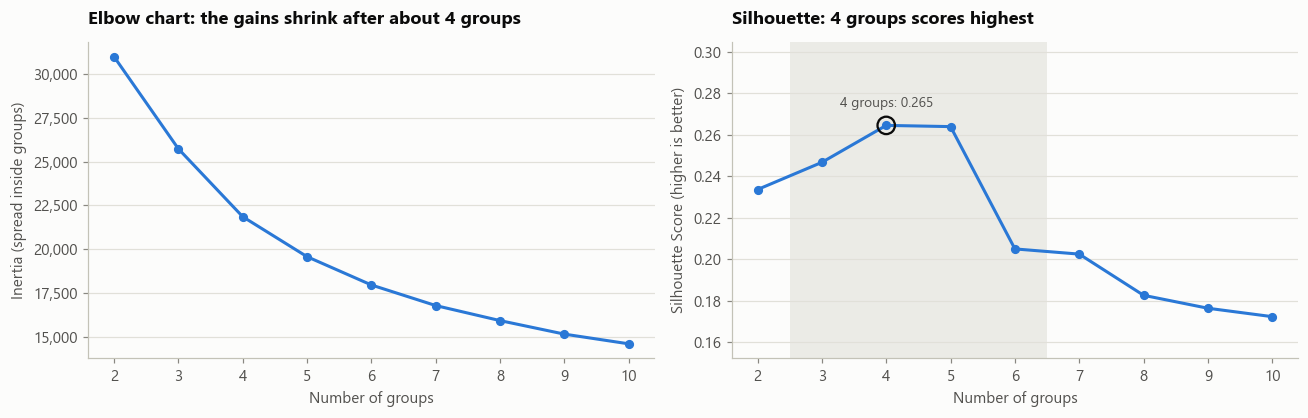

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ks = list(K_RANGE)

ax = axes[0]
ax.plot(ks, kmeans_scores["Inertia"], color=BLUE, linewidth=2, marker="o", markersize=5)
ax.set_title("Elbow chart: the gains shrink after about 4 groups")
ax.set_ylabel("Inertia (spread inside groups)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

ax = axes[1]
ax.axvspan(USABLE_K[0] - 0.5, USABLE_K[-1] + 0.5, color=GRID, alpha=0.6, linewidth=0)
ax.plot(ks, kmeans_scores["Silhouette"], color=BLUE, linewidth=2, marker="o", markersize=5)
ax.scatter([best_k], [kmeans_scores.loc[best_k, "Silhouette"]], s=130, facecolor="none", edgecolor=INK, linewidth=1.5, zorder=3)
ax.annotate(f"{best_k} groups: {kmeans_scores.loc[best_k, 'Silhouette']:.3f}",
            xy=(best_k, kmeans_scores.loc[best_k, "Silhouette"]), xytext=(0, 12),
            textcoords="offset points", ha="center", color=INK_SOFT, fontsize=9)
ax.set_title(f"Silhouette: {best_k} groups scores highest")
ax.set_ylabel("Silhouette Score (higher is better)")
ax.set_ylim(kmeans_scores["Silhouette"].min() - 0.02, kmeans_scores["Silhouette"].max() + 0.04)

for ax in axes:
    ax.set_xlabel("Number of groups")
    ax.set_xticks(ks)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**What we found:**

- **4 groups gives the best Silhouette Score (0.265).** It is the best of all the options from 2 to 10, so limiting ourselves to 3 to 6 groups cost nothing.
- **5 groups is a near tie (0.264).** We take 4: it is the simpler answer, the elbow chart also bends around 4, and after 5 the score falls off a cliff.
- **Calinski-Harabasz prefers 2 groups.** That measure tends to favour fewer, bigger groups on data like this. Two of our three measures point to 4 or 5.
- **A score of about 0.27 is modest.** It means the groups overlap at the edges, which is exactly what the flat maps in Step 3 told us to expect.

### Is the K-Means result stable?

K-Means starts from random centre points, so in principle it could give different groups each time. We re-run it with 10 different random starts and measure how much the groupings agree, using the **Adjusted Rand Index**: 1.0 means the two groupings are identical, 0 means they agree no more than chance.

In [33]:
reference = kmeans_models[best_k].labels_
agreement = [adjusted_rand_score(reference,
                                 KMeans(n_clusters=best_k, n_init=10, random_state=seed).fit(X).labels_)
             for seed in range(10)]
print(f"Agreement across 10 different random starts: average {np.mean(agreement):.3f}, lowest {min(agreement):.3f}")

Agreement across 10 different random starts: average 0.994, lowest 0.990


**What we found:** the groupings agree almost perfectly (0.99 out of 1). K-Means lands on the same four groups no matter where it starts, so the result is not a lucky accident.

## 4.2 Hierarchical clustering

Hierarchical clustering builds a family tree of customers (a **dendrogram**). Reading it from the bottom up, the most similar customers join first. The taller the vertical line before two branches join, the more different those two branches are. Cutting the tree with a horizontal line gives the groups.

It needs a rule for how to measure the distance between two groups, called the **linkage**. We try three and look at the group sizes each one produces.

In [34]:
linkage_rows = []
for method in ["ward", "complete", "average"]:
    labels = AgglomerativeClustering(n_clusters=best_k, linkage=method).fit_predict(X)
    sizes = np.sort(np.bincount(labels))[::-1]
    linkage_rows.append({"Linkage": method, "Silhouette": silhouette_score(X, labels),
                         "Group sizes (customers)": ", ".join(f"{s:,}" for s in sizes),
                         "Largest group (%)": sizes[0] / len(X) * 100})
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(pd.DataFrame(linkage_rows).set_index("Linkage"))

,Silhouette,Group sizes (customers),Largest group (%)
Linkage,,,
ward,0.215,"2,404, 2,138, 1,195, 115",41.080
complete,0.159,"3,593, 2,107, 88, 64",61.398
average,0.374,"5,738, 108, 5, 1",98.052


**A lesson in not trusting one number.** "Average" linkage has by far the highest Silhouette Score, but look at its group sizes: it puts almost every customer in one giant group and peels off a few oddballs. That scores well on paper (a few far-away points are easy to tell apart) and is useless in practice. This is why Step 1 listed "sensible sizes" as a check alongside the scores.

**Ward** linkage gives balanced groups, so we use it from here on.

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest group (%),Largest group (%)
Groups,,,,,
2,0.191,1.772,"1,424.765",41.080,58.920
3,0.196,1.582,"1,311.974",20.420,41.080
4,0.215,1.318,"1,292.640",1.965,41.080
5,0.197,1.473,"1,170.253",1.965,41.080
6,0.163,1.693,"1,116.500",1.965,24.710
7,0.164,1.614,"1,042.195",1.965,24.710
8,0.152,1.659,993.955,1.965,24.710
9,0.140,1.654,947.446,1.965,24.710
10,0.131,1.682,909.626,1.965,20.745


Best Silhouette between 3 and 6 groups: 4 groups (0.215)


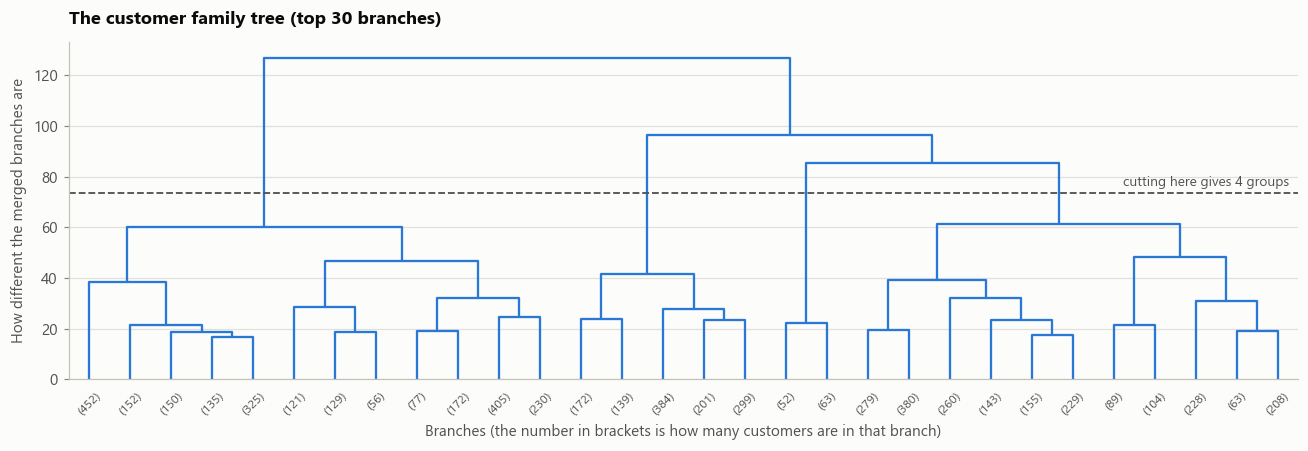

In [35]:
from scipy.cluster.hierarchy import linkage, dendrogram

hier_models, rows = {}, []
for k in K_RANGE:
    model = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
    hier_models[k] = model
    sizes = np.bincount(model.labels_) / len(X) * 100
    rows.append({"Groups": k, **score(model.labels_),
                 "Smallest group (%)": sizes.min(), "Largest group (%)": sizes.max()})
hier_scores = pd.DataFrame(rows).set_index("Groups")
best_k_hier = int(hier_scores.loc[list(USABLE_K), "Silhouette"].idxmax())
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(hier_scores)
print(f"Best Silhouette between {USABLE_K[0]} and {USABLE_K[-1]} groups: {best_k_hier} groups "
      f"({hier_scores.loc[best_k_hier, 'Silhouette']:.3f})")

# The family tree, showing only the last 30 merges so it stays readable
tree = linkage(X, method="ward")
cut_height = (tree[-best_k_hier, 2] + tree[-best_k_hier + 1, 2]) / 2

fig, ax = plt.subplots(figsize=(12, 4.2))
dendrogram(tree, truncate_mode="lastp", p=30, ax=ax, color_threshold=0, above_threshold_color=BLUE,
           show_leaf_counts=True, leaf_font_size=8)
ax.axhline(cut_height, color=INK_SOFT, linestyle="--", linewidth=1.2)
ax.annotate(f"cutting here gives {best_k_hier} groups", xy=(1, cut_height), xycoords=("axes fraction", "data"),
            xytext=(-6, 5), textcoords="offset points", ha="right", color=INK_SOFT, fontsize=9)
ax.set_title("The customer family tree (top 30 branches)")
ax.set_xlabel("Branches (the number in brackets is how many customers are in that branch)")
ax.set_ylabel("How different the merged branches are")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**What we found:** Hierarchical clustering also does best with **4 groups** (Silhouette 0.215), which is reassuring: two different methods agree on the number. Its score is lower than K-Means at every group count, though, and its smallest group holds only 2% of customers.

## 4.3 DBSCAN

DBSCAN does not take a number of groups. Instead it needs two settings:

- **eps:** how close two customers must be to count as neighbours.
- **min_samples:** how many neighbours make a "crowd".

A common rule of thumb sets min_samples to twice the number of features (2 x 7 = 14). To pick eps, we sort customers by the distance to their 14th nearest neighbour and look for the point where that distance starts shooting up. Customers beyond that point are isolated.

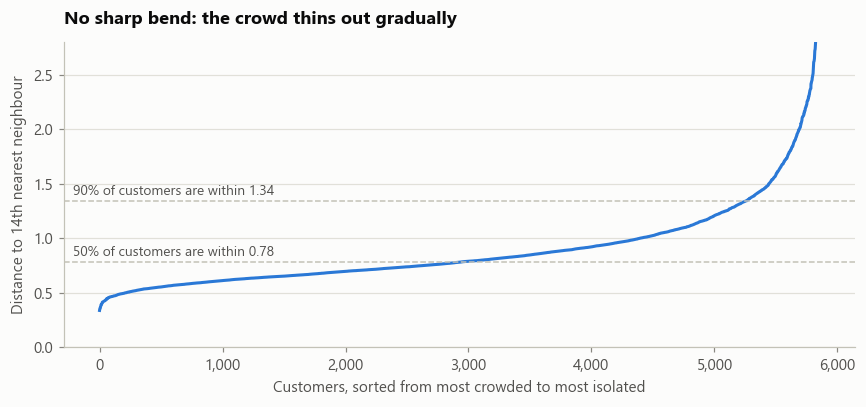

In [36]:
MIN_SAMPLES = 2 * X.shape[1]
kth_distance = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(np.arange(len(kth_distance)), kth_distance, color=BLUE, linewidth=2)
for q in (0.50, 0.90):
    value = np.quantile(kth_distance, q)
    ax.axhline(value, color=AXIS, linestyle="--", linewidth=1)
    ax.annotate(f"{q:.0%} of customers are within {value:.2f}", xy=(0, value), xycoords=("axes fraction", "data"),
                xytext=(6, 4), textcoords="offset points", color=INK_SOFT, fontsize=9)
ax.set_title("No sharp bend: the crowd thins out gradually")
ax.set_xlabel("Customers, sorted from most crowded to most isolated")
ax.set_ylabel(f"Distance to {MIN_SAMPLES}th nearest neighbour")
ax.set_ylim(0, np.quantile(kth_distance, 0.995))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

There is no clear bend to point at, so instead of trusting one guess we try a whole grid of settings and see what DBSCAN finds each time.

In [37]:
dbscan_rows, dbscan_labels = [], {}
for min_samples in [7, 14, 28]:
    for eps in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2, 1.5]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
        grouped = labels != -1
        n_groups = len(set(labels[grouped]))
        sizes = np.bincount(labels[grouped]) if n_groups else np.array([0])
        dbscan_labels[(eps, min_samples)] = labels
        dbscan_rows.append({
            "eps": eps, "min_samples": min_samples, "Groups": n_groups,
            "Noise (%)": (~grouped).mean() * 100,
            "Largest group (% of all customers)": sizes.max() / len(X) * 100,
            # scores are worked out on the customers DBSCAN managed to place in a group
            "Silhouette": silhouette_score(X[grouped], labels[grouped]) if n_groups >= 2 else np.nan,
        })
dbscan_grid = pd.DataFrame(dbscan_rows)

# One compact table: for each setting, how many groups and how much noise
summary = dbscan_grid.assign(Result=lambda d: d["Groups"].astype(str) + np.where(d["Groups"] == 1, " group, ", " groups, ")
                                              + d["Noise (%)"].round(0).astype(int).astype(str) + "% noise")
display(summary.pivot(index="min_samples", columns="eps", values="Result"))

# The "best" DBSCAN we can find: at least 2 groups, at most 15% of customers thrown away as noise
eligible = dbscan_grid[(dbscan_grid["Groups"] >= 2) & (dbscan_grid["Noise (%)"] <= 15)]
best_dbscan = eligible.sort_values("Silhouette", ascending=False).iloc[0]
display(eligible.sort_values("Silhouette", ascending=False).set_index(["eps", "min_samples"]))
print(f"Best DBSCAN setting: eps={best_dbscan['eps']}, min_samples={int(best_dbscan['min_samples'])}")

eps,0.50,0.60,0.70,0.80,0.90,1.00,1.20,1.50
min_samples,,,,,,,,
7,"20 groups, 69% noise","6 groups, 45% noise","10 groups, 27% noise","2 groups, 19% noise","4 groups, 13% noise","1 group, 9% noise","1 group, 5% noise","3 groups, 2% noise"
14,"9 groups, 88% noise","9 groups, 64% noise","1 group, 40% noise","1 group, 26% noise","1 group, 18% noise","1 group, 13% noise","1 group, 7% noise","1 group, 3% noise"
28,"2 groups, 98% noise","4 groups, 87% noise","3 groups, 60% noise","1 group, 36% noise","1 group, 24% noise","1 group, 17% noise","1 group, 9% noise","1 group, 4% noise"


,,Groups,Noise (%),Largest group (% of all customers),Silhouette
eps,min_samples,,,,
1.50,7,3,2.24,97.42,0.53
0.90,7,4,13.06,86.43,0.31


Best DBSCAN setting: eps=1.5, min_samples=7


**What we found:** DBSCAN does not work on this data, and the table shows why. Whatever the settings, it gives one of two unhelpful answers:

- **one giant group plus "noise"** (most of the table), or
- **lots of tiny fragments while most customers are thrown away as noise** (the tight settings on the left).

This is the result we predicted in Step 3. DBSCAN finds groups by looking for empty space between crowds, and our customers form one continuous cloud with no empty space. The best setting we could find has 3 groups, but one of them contains 97% of all customers.

This is a useful finding in its own right: it confirms from a different angle that the customer base is a spectrum, not a set of islands.

## 4.4 Comparing the three methods

The chart puts K-Means and Hierarchical side by side for every number of groups. The table then lines up the best version of each method on all the measures from Step 1, including the practical checks on group size.

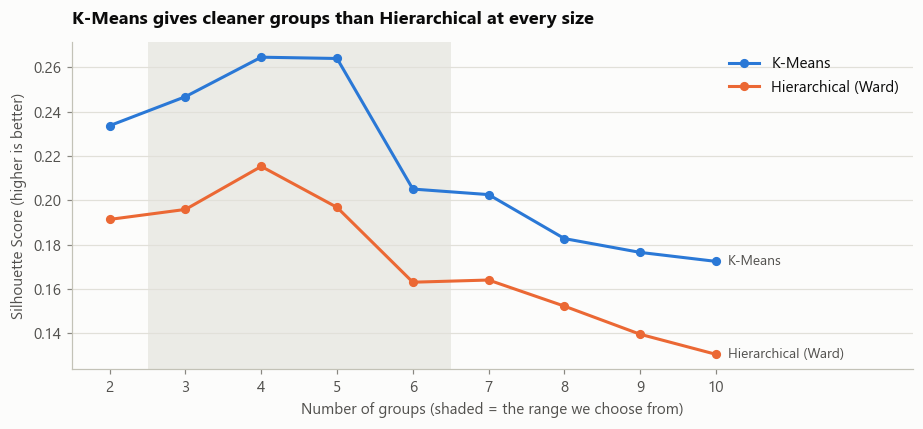

In [38]:
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.axvspan(USABLE_K[0] - 0.5, USABLE_K[-1] + 0.5, color=GRID, alpha=0.6, linewidth=0)
for name, table, colour in [("K-Means", kmeans_scores, BLUE), ("Hierarchical (Ward)", hier_scores, ORANGE)]:
    ax.plot(ks, table["Silhouette"], color=colour, linewidth=2, marker="o", markersize=5, label=name)
    ax.annotate(name, xy=(ks[-1], table["Silhouette"].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK_SOFT, fontsize=9)
ax.set_title("K-Means gives cleaner groups than Hierarchical at every size")
ax.set_xlabel("Number of groups (shaded = the range we choose from)")
ax.set_ylabel("Silhouette Score (higher is better)")
ax.set_xticks(ks)
ax.set_xlim(ks[0] - 0.5, ks[-1] + 2.6)
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [39]:
def describe(name, labels):
    grouped = labels != -1
    sizes = np.bincount(labels[grouped]) / len(labels) * 100
    return {"Model": name, "Groups": len(sizes), **score(labels[grouped], X[grouped]),
            "Largest group (%)": sizes.max(), "Smallest group (%)": sizes.min(),
            "Noise (%)": (~grouped).mean() * 100}

candidates = {
    f"K-Means ({best_k} groups)": kmeans_models[best_k].labels_,
    f"Hierarchical, Ward ({best_k_hier} groups)": hier_models[best_k_hier].labels_,
    f"DBSCAN (eps={best_dbscan['eps']}, min_samples={int(best_dbscan['min_samples'])})":
        dbscan_labels[(best_dbscan["eps"], int(best_dbscan["min_samples"]))],
}
comparison = pd.DataFrame([describe(name, labels) for name, labels in candidates.items()]).set_index("Model")

# Practical check from Step 1: a model is only usable if no single group swallows nearly everyone
comparison["Usable?"] = np.where((comparison["Largest group (%)"] < 90) & (comparison["Noise (%)"] < 10), "yes", "no")
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(comparison)

usable = comparison[comparison["Usable?"] == "yes"]
winner = usable["Silhouette"].idxmax()
print(f"Winner: {winner}")

km_vs_hier = adjusted_rand_score(kmeans_models[best_k].labels_, hier_models[best_k].labels_)
print(f"Agreement between K-Means and Hierarchical at {best_k} groups (1.0 = identical): {km_vs_hier:.2f}")

,Groups,Silhouette,Davies-Bouldin,Calinski-Harabasz,Largest group (%),Smallest group (%),Noise (%),Usable?
Model,,,,,,,,
K-Means (4 groups),4,0.265,1.287,"1,704.327",36.517,3.435,0.000,yes
"Hierarchical, Ward (4 groups)",4,0.215,1.318,"1,292.640",41.080,1.965,0.000,yes
"DBSCAN (eps=1.5, min_samples=7)",3,0.527,0.676,73.296,97.420,0.120,2.239,no


Winner: K-Means (4 groups)
Agreement between K-Means and Hierarchical at 4 groups (1.0 = identical): 0.59


**What we found: K-Means with 4 groups is the winner.**

| Model | Verdict |
|---|---|
| **K-Means (4 groups)** | **Chosen.** Best Silhouette among usable models (0.265), best Calinski-Harabasz, balanced group sizes, stable across re-runs, and it can place new customers. |
| **Hierarchical, Ward (4 groups)** | Usable, but weaker on every score (Silhouette 0.215). |
| **DBSCAN** | Not usable. Its Silhouette looks best on paper (0.53), but only because 97% of customers sit in a single group. Same lesson as "average" linkage earlier. |

K-Means and Hierarchical agree moderately on who belongs where (0.59 out of 1). They find the same broad zones but draw the borders in slightly different places, which is what you would expect when cutting a continuous cloud into pieces.

## 4.5 The final model and its segments

We now take the winning model and look at what kind of customer is in each group. The names are ours: they were chosen after reading the profile table below, and the small set of rules in the code simply makes sure each name sticks to the right group every time the notebook is run.

In [40]:
final_model = kmeans_models[best_k]
customers["Cluster"] = final_model.labels_
centres = X.groupby(customers["Cluster"]).mean()

if best_k == 4:
    left = list(centres.index)
    names = {}
    for name, feature in [("Heavy Returners", "ReturnRate"), ("Loyal Regulars", "Monetary"), ("Lapsed Customers", "Recency")]:
        chosen = centres.loc[left, feature].idxmax()
        names[chosen] = name
        left.remove(chosen)
    names[left[0]] = "New Customers"
else:
    names = {c: f"Segment {c + 1}" for c in centres.index}
customers["Segment"] = customers["Cluster"].map(names)
customers["Silhouette"] = silhouette_samples(X, customers["Cluster"])

profile = customers.groupby("Segment").agg(
    Customers=("Monetary", "size"),
    Days_since_last_order=("Recency", "median"),
    Orders=("Frequency", "median"),
    Total_spend=("Monetary", "median"),
    Products_per_order=("ProductsPerOrder", "median"),
    Price_per_unit=("AvgUnitPrice", "median"),
    Days_as_customer=("Tenure", "median"),
    Return_rate_pct=("ReturnRate", lambda s: s.mean() * 100),
    Sales=("Monetary", "sum"),
    RFM_total_score=("RFM_Total", "mean"),
    Silhouette=("Silhouette", "mean"),
)
profile.insert(1, "% of customers", profile["Customers"] / len(customers) * 100)
profile.insert(2, "% of sales", profile["Sales"] / profile["Sales"].sum() * 100)
profile = profile.drop(columns="Sales").sort_values("% of sales", ascending=False)
profile.columns = [c.replace("_pct", " (%)").replace("_", " ") for c in profile.columns]
SEGMENT_ORDER = list(profile.index)

print("Typical (median) customer in each segment. Return rate, RFM score and Silhouette are averages.")
display(profile.T)

Typical (median) customer in each segment. Return rate, RFM score and Silhouette are averages.


Segment,Loyal Regulars,New Customers,Lapsed Customers,Heavy Returners
Customers,"2,137.00","1,689.00","1,825.00",201.00
% of customers,36.52,28.86,31.19,3.43
% of sales,82.89,7.41,5.80,3.90
Days since last order,33.00,50.00,430.00,276.00
Orders,9.00,2.00,1.00,3.00
Total spend,"2,976.38",542.03,357.72,602.56
Products per order,19.33,18.00,15.00,9.00
Price per unit,1.79,1.69,1.95,2.14
Days as customer,656.00,172.00,564.00,543.00
Return rate (%),1.68,0.77,0.80,36.86


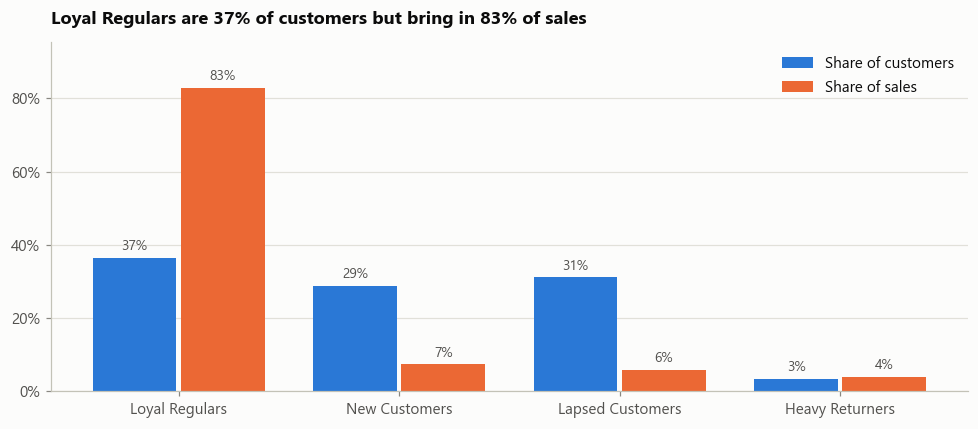

In [41]:
# Share of customers against share of sales
positions = np.arange(len(SEGMENT_ORDER))
fig, ax = plt.subplots(figsize=(9, 4))
for offset, column, colour in [(-0.2, "% of customers", BLUE), (0.2, "% of sales", ORANGE)]:
    bars = ax.bar(positions + offset, profile[column], width=0.38, color=colour, label=column.replace("% of ", "Share of "))
    ax.bar_label(bars, labels=[f"{v:.0f}%" for v in profile[column]], padding=3, color=INK_SOFT, fontsize=9)
ax.set_xticks(positions, SEGMENT_ORDER)
ax.set_title(f"{SEGMENT_ORDER[0]} are {profile['% of customers'].iloc[0]:.0f}% of customers "
             f"but bring in {profile['% of sales'].iloc[0]:.0f}% of sales")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylim(0, profile[["% of customers", "% of sales"]].max().max() * 1.15)
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

The grid below is each segment's "fingerprint". Every number says how far that segment sits above (red) or below (blue) the average customer on each feature, in units of typical spread. Zero means "just like the average customer".

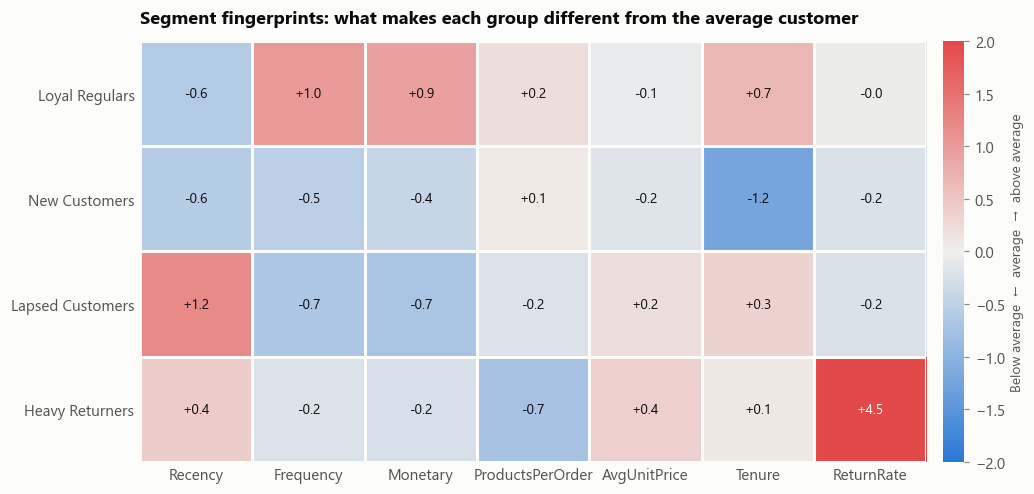

In [42]:
fingerprint = centres.rename(index=names).loc[SEGMENT_ORDER]

fig, ax = plt.subplots(figsize=(9.5, 0.75 * len(SEGMENT_ORDER) + 1.6))
image = ax.imshow(fingerprint, cmap=diverging, vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES)
ax.set_yticks(range(len(SEGMENT_ORDER)), SEGMENT_ORDER)
for i in range(fingerprint.shape[0]):
    for j in range(fingerprint.shape[1]):
        value = fingerprint.iat[i, j]
        ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=9, color="white" if abs(value) > 1.5 else INK)
ax.set_xticks(np.arange(-0.5, len(FEATURES)), minor=True)
ax.set_yticks(np.arange(-0.5, len(SEGMENT_ORDER)), minor=True)
ax.grid(False)
ax.grid(which="minor", color="#fcfcfb", linewidth=2)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
bar = fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
bar.set_label("Below average  ←  average  →  above average", color=INK_SOFT, fontsize=9)
bar.outline.set_visible(False)
ax.set_title("Segment fingerprints: what makes each group different from the average customer")
plt.tight_layout()
plt.show()

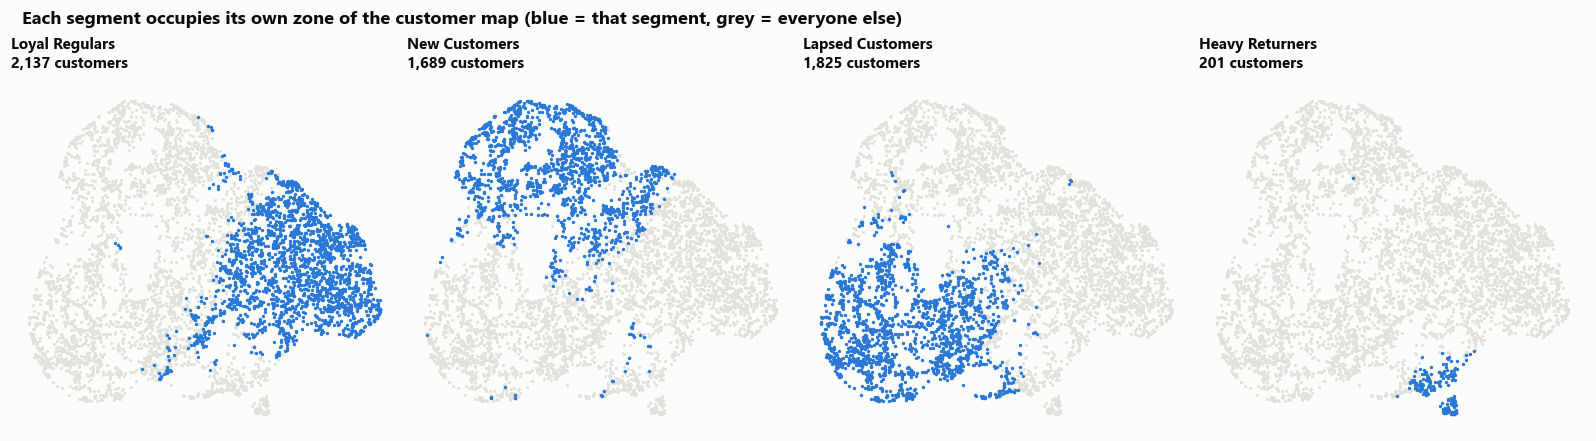

In [43]:
# Where each segment sits on the UMAP map from Step 3 (one panel per segment)
fig, axes = plt.subplots(1, len(SEGMENT_ORDER), figsize=(3.6 * len(SEGMENT_ORDER), 3.9), constrained_layout=True)
for ax, name in zip(np.atleast_1d(axes), SEGMENT_ORDER):
    inside = (customers["Segment"] == name).values
    ax.scatter(embedding.loc[~inside, "UMAP_x"], embedding.loc[~inside, "UMAP_y"], s=4, color=GRID, linewidths=0)
    ax.scatter(embedding.loc[inside, "UMAP_x"], embedding.loc[inside, "UMAP_y"], s=5, color=BLUE, linewidths=0)
    ax.set_title(f"{name}\n{inside.sum():,} customers", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.suptitle("Each segment occupies its own zone of the customer map (blue = that segment, grey = everyone else)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.show()

**What we found: four segments, each with a clear story.**

| Segment | Size | Share of sales | Typical customer | What the business could do |
|---|---|---|---|---|
| **Loyal Regulars** | 2,137 (37%) | **83%** | 9 orders, £2,976 spent, last order about a month ago, a customer for nearly two years | Protect them. Loyalty perks, early access, personal service. A typical Loyal Regular has spent about eight times as much as a typical Lapsed Customer. |
| **New Customers** | 1,689 (29%) | 7% | First bought about six months ago, 2 orders, £542 spent, last order 50 days ago | Nurture them into regulars: welcome offers, suggestions based on first purchases. |
| **Lapsed Customers** | 1,825 (31%) | 6% | 1 order, £358 spent, last seen 430 days ago (over a year) | One low-cost "we miss you" campaign, then stop spending on those who do not respond. |
| **Heavy Returners** | 201 (3%) | 4% | Send back 37% of what they buy on average, against about 1% for everyone else | Investigate before marketing to them: wrong products, quality problems, or wholesale order corrections? |

Some honest notes about these segments:

- **The model adds to classic RFM scoring; it does not contradict it.** The average RFM score falls in a sensible order: Loyal Regulars 12.7 out of 15, New Customers 8.4, Heavy Returners 7.8, Lapsed Customers 5.5. On top of that, the model separates two groups RFM tends to blur (new customers versus lapsed ones, thanks to tenure) and flags returns, which RFM cannot see at all.
- **Heavy Returners are defined almost entirely by one feature.** The fingerprint grid shows them 4.5 units above average on return rate and close to average on everything else. It is a real and useful group, but a simple rule ("returns more than a set share of purchases") would find nearly the same people.
- **Some segments are crisper than others.** Loyal Regulars are the most clear-cut (segment Silhouette 0.33) and Lapsed Customers the fuzziest (0.19). Customers near a border could reasonably be placed in either neighbouring segment.
- **Basket size and unit price barely differ between segments**, matching the Step 3 hint that those two features contribute little.

## 4.6 Saving the models and settings

For reproducibility, everything needed to recreate or reuse the result is saved in the `models/` folder: the trained models, the settings used, and the score tables. The customer list with each customer's segment is saved in `data/processed/`.

One practical advantage of K-Means is worth pointing out: the saved model can place a **brand-new customer** into a segment straight away (prepare their features the same way, then find the nearest centre). Hierarchical clustering and DBSCAN cannot do that without being re-run on everyone.

In [44]:
joblib.dump(final_model, MODEL_DIR / "kmeans_final.joblib")
joblib.dump(hier_models[best_k_hier], MODEL_DIR / "hierarchical_ward.joblib")
joblib.dump(DBSCAN(eps=best_dbscan["eps"], min_samples=int(best_dbscan["min_samples"])).fit(X), MODEL_DIR / "dbscan.joblib")

model_config = {
    "random_state": RANDOM_STATE,
    "features": FEATURES,
    "groups_scored": [K_RANGE[0], K_RANGE[-1]],
    "groups_usable": [USABLE_K[0], USABLE_K[-1]],
    "winner": winner,
    "kmeans": {"n_clusters": best_k, "n_init": 20, "random_state": RANDOM_STATE},
    "hierarchical": {"n_clusters": best_k_hier, "linkage": "ward"},
    "dbscan": {"eps": float(best_dbscan["eps"]), "min_samples": int(best_dbscan["min_samples"])},
    "segment_names": {str(k): v for k, v in names.items()},
}
(MODEL_DIR / "model_config.json").write_text(json.dumps(model_config, indent=2))

comparison.to_csv(MODEL_DIR / "model_comparison.csv")
kmeans_scores.to_csv(MODEL_DIR / "kmeans_scores_by_k.csv")
hier_scores.to_csv(MODEL_DIR / "hierarchical_scores_by_k.csv")
dbscan_grid.to_csv(MODEL_DIR / "dbscan_grid.csv", index=False)
customers.join(embedding).to_csv(DATA_DIR / "customer_segments.csv")

for f in sorted(MODEL_DIR.iterdir()) + [DATA_DIR / "customer_segments.csv"]:
    print(f"Saved {f.relative_to(ROOT).as_posix()}  ({f.stat().st_size / 1024:,.0f} KB)")

Saved models/dbscan.joblib  (397 KB)
Saved models/dbscan_grid.csv  (1 KB)
Saved models/fairness_audit.csv  (1 KB)
Saved models/hierarchical_scores_by_k.csv  (1 KB)
Saved models/hierarchical_ward.joblib  (138 KB)
Saved models/kmeans_final.joblib  (24 KB)
Saved models/kmeans_scores_by_k.csv  (1 KB)
Saved models/model_comparison.csv  (1 KB)
Saved models/model_config.json  (1 KB)
Saved models/preprocessing_config.json  (1 KB)
Saved models/scaler.joblib  (1 KB)
Saved data/processed/customer_segments.csv  (1,271 KB)


## 4.7 Summary of Step 4

| Requirement | What we did | Where |
|---|---|---|
| Experiment with appropriate models | K-Means, Hierarchical (three linkages) and DBSCAN (24 settings) | 4.1 to 4.3 |
| Elbow and Silhouette | Elbow chart and Silhouette chart for 2 to 10 groups | 4.1 |
| Compare with relevant metrics | Silhouette, Davies-Bouldin, Calinski-Harabasz, group sizes, noise, stability across re-runs | 4.4 |
| Reproducibility | Fixed random seed; models, settings and score tables saved in `models/`; segment list saved in `data/processed/` | 4.6 |

**Result:** K-Means with 4 groups, Silhouette Score 0.265. The segments are **Loyal Regulars, New Customers, Lapsed Customers and Heavy Returners**.

**How this stacks up against the success measures from Step 1:**

| Check | Result |
|---|---|
| Silhouette Score | 0.265. Modest, as expected for a continuous customer base. Best of every option tested. |
| Sensible sizes | Three large segments (29% to 37%) and one small specialist segment (3%). |
| Stable | Yes. 0.99 agreement across 10 re-runs. |
| Explainable | Yes. Each segment has a one-line description and a suggested action. |

**Deliverable for Step 4:** trained models (`models/`), metrics, and the comparison between models (section 4.4).

---
# Step 5: Critical Thinking, Ethical AI and Bias Auditing

**What we are doing:** stepping back and asking three hard questions about the model before anyone acts on it.

1. **Can we explain it?** Why does a customer end up in one segment and not another?
2. **Where is it weak?** What are its limits, and what should nobody use it for?
3. **Is it fair?** Does it treat some groups of customers worse than others?

## 5.1 Explaining the model's decisions

K-Means itself is simple (each customer joins the nearest centre), but "nearest in seven dimensions" is not something a person can picture. So we use the same trick as in Step 3, this time on the final model:

1. Train a second, "explainer" model (a random forest) to **predict each customer's final segment** from their features.
2. Check that it copies the real segments faithfully. If it does, explaining the copy explains the original.
3. Take the explainer apart with **SHAP** (which features matter, and for which segment) and **what-if curves** (how the answer changes as one feature changes).

The explainer is trained on the features in their everyday units (days, orders, pounds), so the charts are readable.

In [45]:
explain_data = customers[FEATURES].astype(float)
explainer_model = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

fidelity = cross_val_score(explainer_model, explain_data, customers["Segment"], cv=5).mean()
explainer_model.fit(explain_data, customers["Segment"])
print(f"On customers it has not seen, the explainer predicts the real segment correctly {fidelity:.1%} of the time.")

sample = explain_data.sample(1000, random_state=RANDOM_STATE)
tree_explainer = shap.TreeExplainer(explainer_model)

def shap_array(rows):
    # SHAP values as (customers, features, segments), whatever format the library returns
    values = tree_explainer.shap_values(rows)
    return np.stack(values, axis=-1) if isinstance(values, list) else np.asarray(values)

shap_sample = shap_array(sample)
importance_by_segment = pd.DataFrame(np.abs(shap_sample).mean(axis=0), index=FEATURES,
                                     columns=explainer_model.classes_)[SEGMENT_ORDER].T
overall_importance = importance_by_segment.mean().sort_values(ascending=False)
display(overall_importance.rename("Average influence across segments").to_frame().T)

On customers it has not seen, the explainer predicts the real segment correctly 97.3% of the time.


,Recency,Tenure,Frequency,Monetary,ReturnRate,ProductsPerOrder,AvgUnitPrice
Average influence across segments,0.13,0.10,0.08,0.06,0.04,0.01,0.01


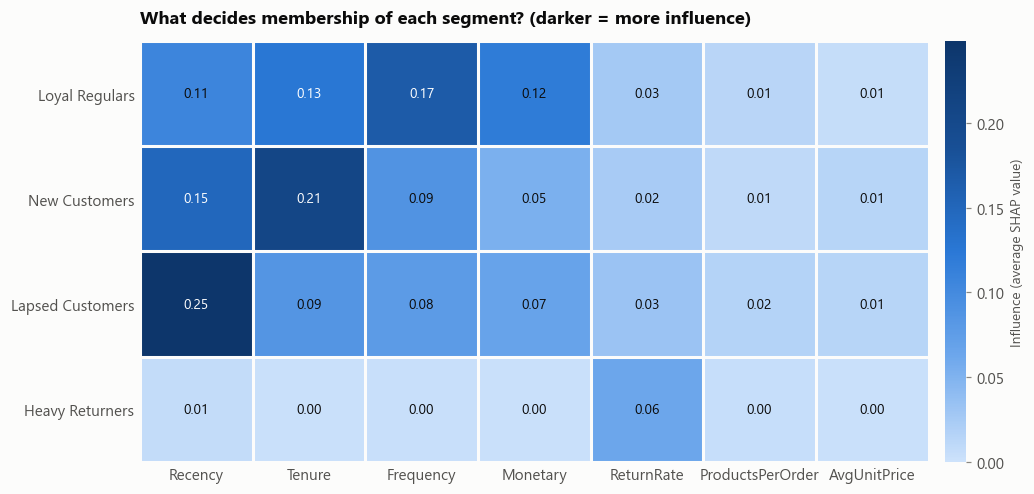

In [46]:
ordered = importance_by_segment[overall_importance.index]

fig, ax = plt.subplots(figsize=(9.5, 0.75 * len(SEGMENT_ORDER) + 1.6))
image = ax.imshow(ordered, cmap=sequential, vmin=0, aspect="auto")
ax.set_xticks(range(ordered.shape[1]), ordered.columns)
ax.set_yticks(range(ordered.shape[0]), ordered.index)
for i in range(ordered.shape[0]):
    for j in range(ordered.shape[1]):
        value = ordered.iat[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9,
                color="white" if value > ordered.values.max() * 0.5 else INK)
ax.set_xticks(np.arange(-0.5, ordered.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, ordered.shape[0]), minor=True)
ax.grid(False)
ax.grid(which="minor", color="#fcfcfb", linewidth=2)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
bar = fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
bar.set_label("Influence (average SHAP value)", color=INK_SOFT, fontsize=9)
bar.outline.set_visible(False)
ax.set_title("What decides membership of each segment? (darker = more influence)")
plt.tight_layout()
plt.show()

**What we found:**

- **The explainer is a faithful copy.** It predicts the real segment correctly for 97% of customers it has not seen, so its explanations can be trusted to describe the K-Means model.
- **Each segment has its own deciding feature**, and they match the names we gave:
  - **Lapsed Customers** are decided almost entirely by **Recency** (how long since the last order).
  - **New Customers** are decided mainly by **Tenure** (how recently they first bought), then Recency.
  - **Loyal Regulars** are decided by a mix, led by **Frequency**, then Tenure, Monetary and Recency.
  - **Heavy Returners** are decided by **Return rate** and nothing else.
- **Basket size and unit price have almost no influence**, for any segment. A simpler model without them would give nearly the same answer.

### What-if curves (PDP and ICE)

SHAP says *which* features matter. What-if curves show *how*. We take real customers, change just one of their features across its range while leaving everything else alone, and watch what happens to their chance of being placed in **Loyal Regulars**.

- Each **thin grey line** is one real customer (an "ICE" curve: individual conditional expectation).
- The **thick blue line** is the average of all of them (the "PDP": partial dependence plot).

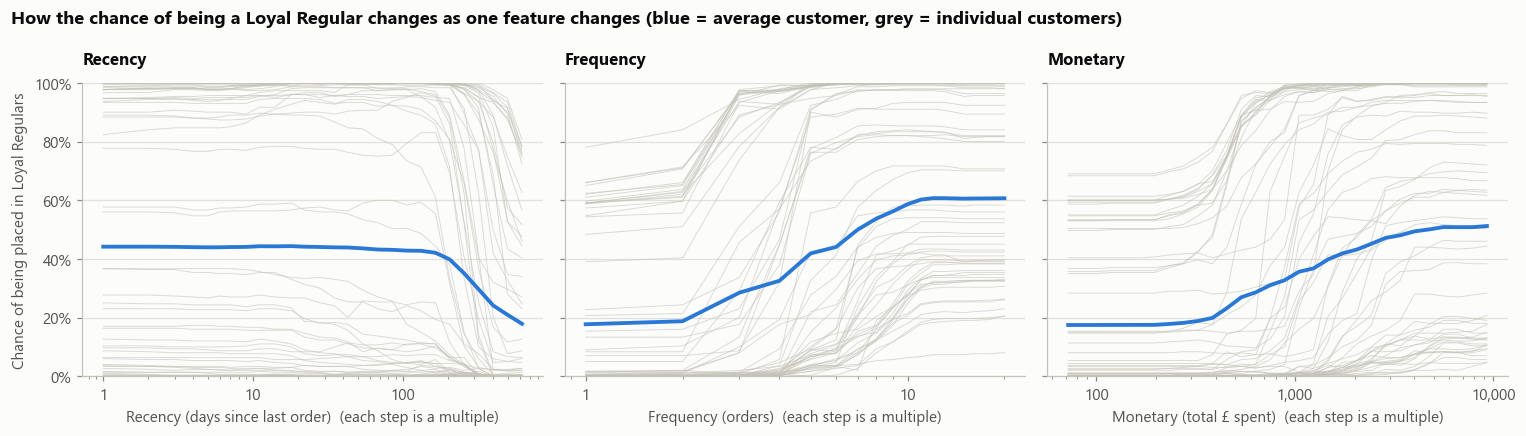

In [47]:
target = list(explainer_model.classes_).index("Loyal Regulars") if "Loyal Regulars" in explainer_model.classes_ else 0
target_name = explainer_model.classes_[target]
people = explain_data.sample(300, random_state=RANDOM_STATE)

def what_if(feature, grid):
    # Chance of landing in the target segment as one feature is changed and the rest are left alone
    curves = np.empty((len(people), len(grid)))
    for j, value in enumerate(grid):
        changed = people.copy()
        changed[feature] = value
        curves[:, j] = explainer_model.predict_proba(changed)[:, target]
    return curves * 100

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, feature in zip(axes, ["Recency", "Frequency", "Monetary"]):
    low, high = explain_data[feature].quantile([0.02, 0.95])
    grid = np.unique(np.round(np.geomspace(max(low, 1), high, 30), 0))
    curves = what_if(feature, grid)
    ax.plot(grid, curves[:60].T, color=AXIS, linewidth=0.6, alpha=0.6)
    ax.plot(grid, curves.mean(axis=0), color=BLUE, linewidth=2.5)
    ax.set_xscale("log")
    ax.set_title(feature, fontsize=11)
    ax.set_xlabel(NICE[feature] + "  (each step is a multiple)")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.set_ylim(0, 100)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel(f"Chance of being placed in {target_name}")
fig.suptitle(f"How the chance of being a {target_name[:-1]} changes as one feature changes "
             "(blue = average customer, grey = individual customers)", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

**What we found:**

- **Recency has a cliff, not a slope.** It makes little difference whether the last order was 2 days or 100 days ago. Past roughly 150 to 200 days the chance of being a Loyal Regular drops sharply.
- **Frequency matters most between 2 and 10 orders.** Going from 2 orders to about 10 lifts the average chance from under 20% to about 60%. Beyond that, extra orders add nothing.
- **Monetary starts to count at about £400** and levels off around £5,000.
- **The grey lines are far from identical**, which is the useful part of an ICE chart. Some customers sit near 100% whatever happens to one feature, others near 0%. No single feature decides the outcome on its own; it is the combination that counts.

### Explaining one customer

The same tools can explain a single decision, which is what a customer service agent or the customer themselves would actually ask for: *"why am I in this segment?"*

Below we take one customer and show how each of their features pushed the model **towards** (blue) or **away from** (red) the segment they were given.

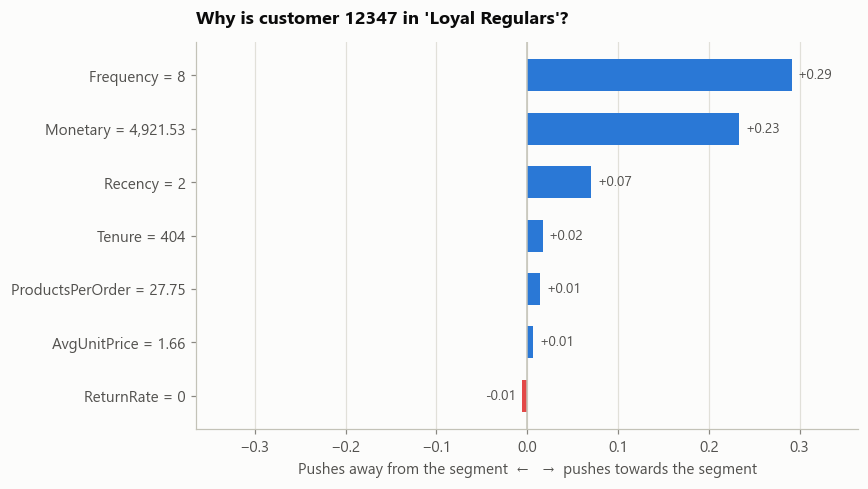

In [48]:
example_id = customers.index[1]
example_segment = customers.loc[example_id, "Segment"]
example_shap = pd.Series(
    shap_array(explain_data.loc[[example_id]])[0, :, list(explainer_model.classes_).index(example_segment)],
    index=FEATURES,
).sort_values(key=np.abs)

def pretty(value):
    return f"{value:,.0f}" if float(value).is_integer() else f"{value:,.2f}"

labels = [f"{name} = {pretty(explain_data.loc[example_id, name])}" for name in example_shap.index]
fig, ax = plt.subplots(figsize=(8, 0.45 * len(FEATURES) + 1.4))
bars = ax.barh(labels, example_shap.values, color=np.where(example_shap.values >= 0, BLUE, "#e34948"), height=0.6)
ax.bar_label(bars, labels=[f"{v:+.2f}" for v in example_shap.values], padding=4, color=INK_SOFT, fontsize=9)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_title(f"Why is customer {example_id} in '{example_segment}'?")
ax.set_xlabel("Pushes away from the segment  ←   →  pushes towards the segment")
reach = np.abs(example_shap.values).max() * 1.25
ax.set_xlim(-reach, reach)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**What we found:** customer 12347 is a Loyal Regular mainly because of their **8 orders** and **£4,922 total spend**, with a small extra push from having ordered just 2 days ago. Nothing about them argues against it. An explanation like this can be produced for any customer, which matters if a customer or a manager ever asks why someone was treated a certain way.

## 5.2 Limitations

No model should be handed over without a clear list of what it cannot do. We test two limits with data, then list the rest.

### Does the model hold up on customers it has never seen? (overfitting check)

"Overfitting" means a model has memorised the quirks of the data it was built on and falls apart on anyone new. To test this we hide 30% of customers, build the segments from the other 70%, then ask: do the hidden customers get sorted the same way as when the model was built on everybody?

In [49]:
from sklearn.model_selection import train_test_split

seen, unseen = train_test_split(X.index, test_size=0.30, random_state=RANDOM_STATE)
partial_model = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE).fit(X.loc[seen])

same_answer = adjusted_rand_score(final_model.predict(X.loc[unseen]), partial_model.predict(X.loc[unseen]))
print(f"Agreement on the hidden 30% of customers (1.0 = identical): {same_answer:.3f}")
print(f"Silhouette on the 70% the model was built on: {silhouette_score(X.loc[seen], partial_model.labels_):.3f}")
print(f"Silhouette on the hidden 30%:                 {silhouette_score(X.loc[unseen], partial_model.predict(X.loc[unseen])):.3f}")

Agreement on the hidden 30% of customers (1.0 = identical): 0.992


Silhouette on the 70% the model was built on: 0.265
Silhouette on the hidden 30%:                 0.264


**What we found:** the model holds up. Customers it had never seen are sorted the same way (0.99 agreement out of 1), and the Silhouette Score is practically the same on seen and unseen customers (0.265 against 0.264). There is no sign of overfitting.

### Who is missing from the picture? (selection bias)

In Step 3 we removed every row with no customer number, because it could not be tied to a customer. That was necessary, but it means the model has only ever seen **identified** customers. If the missing rows are a different kind of shopper, the segments do not describe the whole business.

In [50]:
real_sales = raw[(raw["Quantity"] > 0) & (raw["Price"] > 0)].copy()
real_sales["Value"] = real_sales["Quantity"] * real_sales["Price"]
real_sales["No customer number"] = real_sales["Customer ID"].isna()
real_sales["Location"] = np.where(real_sales["Country"] == "United Kingdom", "UK", "Non-UK")

print(f"Share of sales value with no customer number: "
      f"{real_sales.loc[real_sales['No customer number'], 'Value'].sum() / real_sales['Value'].sum():.1%}")
display(real_sales.groupby("Location").agg(
    Rows=("Value", "size"),
    Rows_without_customer_number_pct=("No customer number", lambda s: s.mean() * 100),
).rename(columns={"Rows_without_customer_number_pct": "Rows without a customer number (%)"}))

Share of sales value with no customer number: 15.1%


,Rows,Rows without a customer number (%)
Location,,
Non-UK,82022,3.49
UK,937633,24.08


**What we found:** the missing rows are not a random sample.

- **15% of all sales value** has no customer number and is invisible to the model.
- **It is almost entirely a UK issue.** 24% of UK rows have no customer number, against only 3.5% of non-UK rows. The likely reason is that UK shoppers can buy without an account, while overseas orders nearly always go through one.

So the segments describe **customers with an account**, not everyone who buys. Casual UK shoppers who check out as guests are under-represented, and the audit below can only speak for identified customers.

### The full list of limitations

| Limitation | What it means here | How serious |
|---|---|---|
| **Imbalance** | The segments are uneven (37%, 31%, 29% and 3%), and one country holds 91% of customers. The 201 Heavy Returners and the 518 non-UK customers are small groups, so figures about them are less certain. | Moderate. Margins of error are reported in the audit. |
| **Leakage** | In prediction tasks, leakage means the model secretly sees the answer. There is no answer column in clustering, so the classic problem cannot occur. The nearest risk is circular reasoning: the RFM scores used as a yardstick in the audit are built from the same data as the model. | Low, but stated wherever it applies. |
| **Overfitting** | Tested above. The model sorts unseen customers the same way. | Low. |
| **Overlapping segments** | A Silhouette Score of 0.265 means customers near a border could fairly belong to either neighbouring segment. | Moderate. Do not treat a segment label as a hard fact about a person. |
| **A snapshot in time** | Recency and Tenure are counted from 10 December 2011, just after the Christmas peak. Run it in July and some customers would move. A "New Customer" becomes something else simply by waiting. | Moderate. The segments need refreshing regularly, for example every quarter. |
| **Selection bias** | Guest purchases (15% of sales value, mostly UK) are excluded. | Moderate. See above. |
| **Wholesalers and individuals mixed** | Many customers are businesses. A shop buying stock and a person buying a gift are measured on the same scale. | Moderate. A business or consumer flag would help if one existed. |
| **Explanations are of a copy** | SHAP and the what-if curves explain the random forest that imitates K-Means, not K-Means itself. | Low, because the copy is 97% faithful. |
| **Association, not cause** | The model describes how customers have behaved. It does not show that perks would *cause* anyone to spend more. | High for decision-making. Campaigns should be tested on a small group first. |

## 5.3 Bias and fairness audit

### What can and cannot be audited

A fairness audit checks whether a model's results differ between groups of people that should be treated equally, such as men and women, or different age groups.

**This dataset contains no gender, race, age or income information.** We cannot test for bias on those characteristics, and we will not guess them from other data. That is a genuine limit of this audit, not a clean bill of health.

The one personal characteristic we do have is **country**, so the audit asks: **are customers outside the UK treated differently from UK customers?** Two things make this a fair test:

- Country was deliberately **kept out of the model** in Step 3, so any difference comes from behaviour, not from the model being told where people live.
- Segments lead to real consequences. Loyal Regulars would get perks and attention; Lapsed Customers would get less marketing; Heavy Returners might get extra scrutiny.

### First look: which segments do UK and non-UK customers land in?

Segment,Loyal Regulars,New Customers,Lapsed Customers,Heavy Returners,Total
Location,,,,,
UK,1959,1503,1693,179,5334
Non-UK,178,186,132,22,518


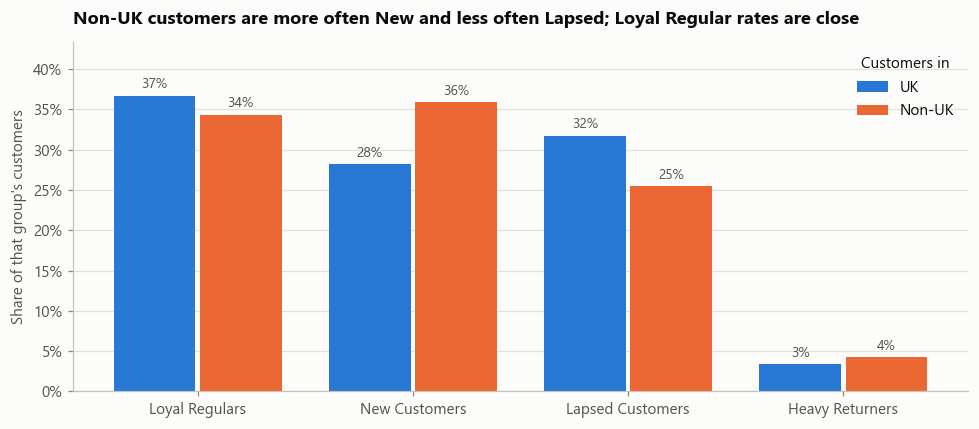

Chance that a difference this large is pure coincidence (chi-square test): 0.0006


In [51]:
from scipy.stats import chi2_contingency

customers["Location"] = np.where(customers["IsUK"] == 1, "UK", "Non-UK")
GROUPS = ["UK", "Non-UK"]
is_uk = customers["Location"] == "UK"

counts = pd.crosstab(customers["Segment"], customers["Location"]).loc[SEGMENT_ORDER, GROUPS]
shares = counts / counts.sum() * 100
display(counts.T.assign(Total=counts.sum()))

def grouped_bars(table, title, xlabel=None, ylabel=None, legend="upper right"):
    # Two bars per category: UK in blue, Non-UK in orange
    positions = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(9, 4))
    for offset, group, colour in [(-0.2, "UK", BLUE), (0.2, "Non-UK", ORANGE)]:
        bars = ax.bar(positions + offset, table[group], width=0.38, color=colour, label=group)
        ax.bar_label(bars, labels=[f"{v:.0f}%" for v in table[group]], padding=3, color=INK_SOFT, fontsize=9)
    ax.set_xticks(positions, table.index)
    ax.set_title(title)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.set_ylim(0, table[GROUPS].max().max() * 1.18)
    ax.legend(frameon=False, loc=legend, title="Customers in")
    ax.grid(axis="x", visible=False)
    plt.tight_layout()
    plt.show()

grouped_bars(shares, "Non-UK customers are more often New and less often Lapsed; Loyal Regular rates are close",
             ylabel="Share of that group's customers")

p_value = chi2_contingency(counts)[1]
print(f"Chance that a difference this large is pure coincidence (chi-square test): {p_value:.4f}")

**What we found:** the two groups are not spread across the segments in exactly the same way, and the difference is too large to be coincidence (less than a 1 in 1,000 chance). But look at where the differences are:

- **Non-UK customers are more often New Customers** (36% against 28%) and **less often Lapsed** (25% against 32%).
- **For Loyal Regulars the rates are close** (34% against 37%).

The next section puts numbers on whether any of this amounts to unfair treatment.

### Fairness measure 1: demographic parity and disparate impact

**Demographic parity** asks a simple question: does each group get the good outcome at the same rate? Two numbers summarise it:

- **Parity difference:** the non-UK rate minus the UK rate. Zero is perfectly equal.
- **Disparate impact ratio:** the non-UK rate divided by the UK rate. One is perfectly equal. A widely used rule of thumb, the **"four-fifths rule"**, raises a flag when the ratio falls below 0.80 (or, turned the other way, rises above 1.25).

We check the good outcome (Loyal Regulars) and the two outcomes that could work against a customer (Lapsed Customers and Heavy Returners). Because there are only 518 non-UK customers, we also give a **margin of error** for each ratio: the range it would plausibly fall in if we could repeat the study.

In [52]:
def fairness_row(outcome, kind, flag):
    uk, non_uk = flag[is_uk], flag[~is_uk]
    rng = np.random.default_rng(RANDOM_STATE)
    # Margin of error by simulation: redraw each group 5,000 times at its observed rate
    sims = (rng.binomial(len(non_uk), non_uk.mean(), 5000) / len(non_uk)) / (rng.binomial(len(uk), uk.mean(), 5000) / len(uk))
    low, high = np.percentile(sims, [2.5, 97.5])
    ratio = non_uk.mean() / uk.mean()
    if low <= 1 <= high:
        verdict = "No reliable difference"
    elif 0.8 <= ratio <= 1.25:
        verdict = "Small difference, within the four-fifths rule"
    else:
        verdict = "Flag: outside the four-fifths rule"
    return {"Outcome": outcome, "Kind of outcome": kind,
            "UK rate (%)": uk.mean() * 100, "Non-UK rate (%)": non_uk.mean() * 100,
            "Parity difference (points)": (non_uk.mean() - uk.mean()) * 100,
            "Disparate impact ratio": ratio, "Margin of error": f"{low:.2f} to {high:.2f}", "Reading": verdict}

parity = pd.DataFrame([
    fairness_row("Loyal Regulars", "Favourable (perks)", customers["Segment"] == "Loyal Regulars"),
    fairness_row("Lapsed Customers", "Unfavourable (less marketing)", customers["Segment"] == "Lapsed Customers"),
    fairness_row("Heavy Returners", "Unfavourable (extra scrutiny)", customers["Segment"] == "Heavy Returners"),
]).set_index("Outcome")
with pd.option_context("display.max_colwidth", None):
    display(parity)

,Kind of outcome,UK rate (%),Non-UK rate (%),Parity difference (points),Disparate impact ratio,Margin of error,Reading
Outcome,,,,,,,
Loyal Regulars,Favourable (perks),36.73,34.36,-2.36,0.94,0.82 to 1.05,No reliable difference
Lapsed Customers,Unfavourable (less marketing),31.74,25.48,-6.26,0.80,0.68 to 0.93,"Small difference, within the four-fifths rule"
Heavy Returners,Unfavourable (extra scrutiny),3.36,4.25,0.89,1.27,0.77 to 1.87,No reliable difference


**What we found:**

| Outcome | Result | Reading |
|---|---|---|
| **Loyal Regulars** (the good outcome) | Ratio 0.94, margin of error 0.82 to 1.05 | **Passes.** Well above the 0.80 line, and the margin of error includes 1, so we cannot say the two groups are treated differently at all. |
| **Lapsed Customers** | Ratio 0.80, margin of error 0.68 to 0.93 | A real difference, and it runs **in favour of non-UK customers**: they are less often labelled Lapsed. It sits right on the four-fifths line. |
| **Heavy Returners** | Ratio 1.27, margin of error 0.77 to 1.87 | **Inconclusive.** Non-UK customers appear here slightly more often (4.3% against 3.4%), but that is only 22 people and the margin of error is very wide. Worth watching, not proven. |

On the headline numbers, **the model does not disadvantage customers outside the UK**.

### Fairness measure 2: equalised odds

Demographic parity ignores whether people *deserve* the outcome. **Equalised odds** goes a step further: among customers who truly are high-value, does each group have the same chance of being recognised as such? And among those who are not, does each group have the same chance of being let in anyway?

**The catch:** clustering has no "true answer" to check against. As a stand-in we use the classic RFM scores from Step 3 and call a customer **"high-value on paper"** if they score 4 or 5 on all three of Recency, Frequency and Monetary. This is an imperfect yardstick, because it is built from the same information the model uses, so treat this measure as a consistency check and not as proof.

In [53]:
customers["HighValueOnPaper"] = (customers[["R_Score", "F_Score", "M_Score"]] >= 4).all(axis=1)
loyal = customers["Segment"] == "Loyal Regulars"

odds = pd.DataFrame({
    "High-value on paper (customers)": customers.groupby("Location")["HighValueOnPaper"].sum(),
    "Recognised: high-value AND placed in Loyal Regulars (%)":
        loyal[customers["HighValueOnPaper"]].groupby(customers["Location"]).mean() * 100,
    "Let in anyway: not high-value BUT placed in Loyal Regulars (%)":
        loyal[~customers["HighValueOnPaper"]].groupby(customers["Location"]).mean() * 100,
}).loc[GROUPS].T
odds["Gap (points)"] = odds["Non-UK"] - odds["UK"]
odds.loc["High-value on paper (customers)", "Gap (points)"] = np.nan
display(odds)

Location,UK,Non-UK,Gap (points)
High-value on paper (customers),"1,172.00",112.00,NaN
Recognised: high-value AND placed in Loyal Regulars (%),90.53,91.07,0.54
Let in anyway: not high-value BUT placed in Loyal Regulars (%),21.58,18.72,-2.86


**What we found:** the two groups are treated almost identically on this measure.

- **Truly high-value customers are recognised equally often:** 91% in both groups (a gap of half a percentage point).
- **Customers who are not high-value on paper are let in at similar rates:** 22% for UK, 19% for non-UK.

Both gaps are under 3 percentage points. Bearing in mind that the yardstick is imperfect, equalised odds is satisfied.

### Looking underneath the headline: same spend, same treatment?

Headline rates can hide things. A sharper question is: **if a UK customer and a non-UK customer have spent about the same amount, are they equally likely to be called a Loyal Regular?**

To answer it we use the spending grade from Step 3 (1 = lowest-spending fifth of customers, 5 = highest-spending fifth) and compare the two groups within each grade.

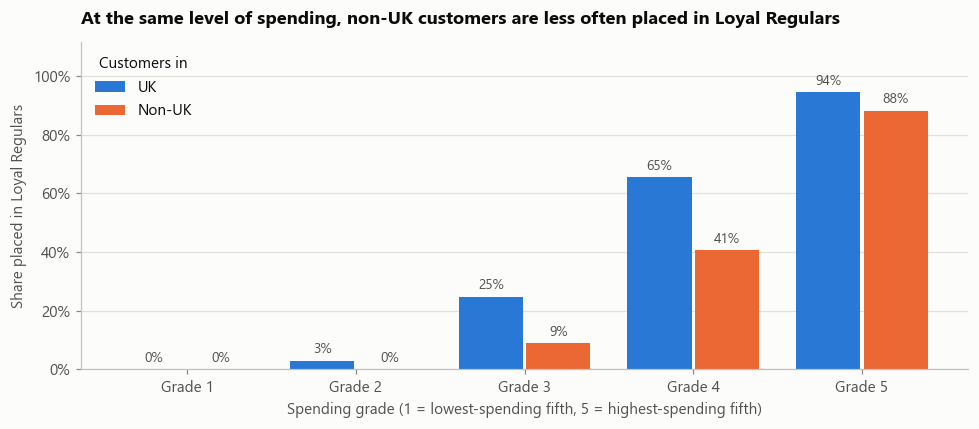

Location,UK,Non-UK
Customers,"5,334.00",518.00
Typical total spend,829.44,"1,139.82"
Typical number of orders,3.00,3.00
Average number of orders,6.25,6.24
Typical order value,269.64,395.87
Typical days since last order,96.00,78.50


Typical customer within each spending grade:


Customers  Typical number of orders  Typical order value
M_Score Location                                                          
3       Non-UK          114                      2.00               373.32
        UK             1056                      3.00               273.68
4       Non-UK          101                      4.00               461.45
        UK             1069                      6.00               318.95
5       Non-UK          144                      8.00               730.10
        UK             1027                     13.00               429.26

In [54]:
by_grade = (loyal.groupby([customers["M_Score"], customers["Location"]]).mean().unstack() * 100)[GROUPS]
by_grade.index = [f"Grade {g}" for g in by_grade.index]
grade_sizes = customers.groupby(["M_Score", "Location"]).size().unstack()[GROUPS]

grouped_bars(by_grade, "At the same level of spending, non-UK customers are less often placed in Loyal Regulars",
             xlabel="Spending grade (1 = lowest-spending fifth, 5 = highest-spending fifth)",
             ylabel="Share placed in Loyal Regulars", legend="upper left")

habits = customers.groupby("Location").agg(
    Customers=("Monetary", "size"),
    Typical_total_spend=("Monetary", "median"),
    Typical_number_of_orders=("Frequency", "median"),
    Average_number_of_orders=("Frequency", "mean"),
    Typical_order_value=("AvgOrderValue", "median"),
    Typical_days_since_last_order=("Recency", "median"),
).loc[GROUPS]
habits.columns = [c.replace("_", " ") for c in habits.columns]
display(habits.T)

# The same comparison inside the top three spending grades
print("Typical customer within each spending grade:")
within_grade = customers[customers["M_Score"] >= 3].groupby(["M_Score", "Location"]).agg(
    Customers=("Monetary", "size"),
    Typical_number_of_orders=("Frequency", "median"),
    Typical_order_value=("AvgOrderValue", "median"),
)
within_grade.columns = [c.replace("_", " ") for c in within_grade.columns]
display(within_grade)

**What we found: the headline numbers were hiding something.**

At the same level of spending, non-UK customers are clearly **less** likely to be placed in Loyal Regulars. In spending grade 4, 65% of UK customers are Loyal Regulars against 41% of non-UK customers. In grade 3 it is 25% against 9%.

**Why does this happen?** Overseas customers shop differently. They place **fewer but larger orders**: a typical grade 4 customer abroad has placed 4 orders of about £461 each, while a typical UK one has placed 6 orders of about £319. That is sensible behaviour when shipping abroad is slow and costly. But the model counts the *number of orders* (Frequency) as a sign of loyalty, so two customers who have spent the same money get different labels.

**Why did the headline numbers look fine?** Because non-UK customers also spend more overall (a typical £1,140 against £829), so more of them sit in the top spending grades where almost everyone is a Loyal Regular. The two effects cancel out in the total. This is a well-known trap in statistics: a gap can vanish in the overall figure and still exist inside every subgroup.

**Is this unfair?** It is a judgement call, and it should be made by the business, not hidden by the model:

- One view: ordering often is a genuine sign of engagement, so the model is right.
- The other view: the business cares about revenue, and a customer should not lose out because of how they bundle their orders, especially when that is driven by where they live.

We take the second concern seriously enough to test a fix below.

### A closer look at individual countries

"Non-UK" lumps together more than 40 countries. The table shows the largest ones. **Read it with caution:** most have only 20 to 100 customers, so a handful of customers can swing the percentages a long way.

In [55]:
biggest = customers.loc[~is_uk, "Country"].value_counts().head(8).index
by_country_segment = customers[customers["Country"].isin(biggest)].groupby("Country").agg(
    Customers=("Monetary", "size"),
    Loyal_Regulars_pct=("Segment", lambda s: (s == "Loyal Regulars").mean() * 100),
    Lapsed_Customers_pct=("Segment", lambda s: (s == "Lapsed Customers").mean() * 100),
    Typical_number_of_orders=("Frequency", "median"),
    Typical_total_spend=("Monetary", "median"),
).sort_values("Customers", ascending=False)
uk_row = pd.DataFrame({
    "Customers": [is_uk.sum()],
    "Loyal_Regulars_pct": [loyal[is_uk].mean() * 100],
    "Lapsed_Customers_pct": [(customers.loc[is_uk, "Segment"] == "Lapsed Customers").mean() * 100],
    "Typical_number_of_orders": [customers.loc[is_uk, "Frequency"].median()],
    "Typical_total_spend": [customers.loc[is_uk, "Monetary"].median()],
}, index=["United Kingdom (for comparison)"])
by_country_segment = pd.concat([uk_row, by_country_segment])
by_country_segment.columns = [c.replace("_pct", " (%)").replace("_", " ") for c in by_country_segment.columns]
display(by_country_segment)

,Customers,Loyal Regulars (%),Lapsed Customers (%),Typical number of orders,Typical total spend
United Kingdom (for comparison),5334,36.73,31.74,3.00,829.44
Germany,106,43.40,14.15,3.00,"1,319.45"
France,93,31.18,16.13,3.00,926.17
Spain,35,25.71,25.71,2.00,832.39
Belgium,28,39.29,25.00,4.00,"1,339.16"
Portugal,23,30.43,30.43,2.00,893.90
Netherlands,22,22.73,68.18,3.00,756.07
Switzerland,22,50.00,9.09,3.00,"2,568.47"
Sweden,19,21.05,57.89,1.00,757.59


**What we found:** results vary a lot from country to country. Germany and Switzerland have more Loyal Regulars than the UK, while the Netherlands and Sweden show very high shares of Lapsed Customers. With only 19 to 22 customers in those countries, though, these figures could easily be chance. The safe conclusions are that "non-UK" is not one uniform group, and that any country-level decision would need more data.

### Trying out a mitigation: a spend-based safety net

One standard family of fixes is **post-processing**: leave the model alone, and adjust how its output is *used*. Here that means changing who qualifies for loyalty perks.

**The rule we test:** a customer qualifies for perks if they are a Loyal Regular, **or** if they are both a high spender (spending grade 4 or 5) and a recent buyer (recency grade 4 or 5), however many separate orders they placed.

The idea is that a customer who spends a lot and bought recently should not miss out just because they place a few large orders instead of many small ones.

In [56]:
safety_net = (customers["M_Score"] >= 4) & (customers["R_Score"] >= 4)
customers["PerksBefore"] = loyal
customers["PerksAfter"] = loyal | safety_net

def perks_summary(flag):
    uk, non_uk = flag[is_uk].mean(), flag[~is_uk].mean()
    grade4 = flag[customers["M_Score"] == 4].groupby(customers["Location"]).mean() * 100
    return {"Customers who qualify": int(flag.sum()),
            "UK rate (%)": uk * 100, "Non-UK rate (%)": non_uk * 100,
            "Disparate impact ratio": non_uk / uk,
            "Spending grade 4: UK rate (%)": grade4["UK"], "Spending grade 4: Non-UK rate (%)": grade4["Non-UK"],
            "Spending grade 4: gap (points)": grade4["Non-UK"] - grade4["UK"]}

mitigation = pd.DataFrame({"Before (Loyal Regulars only)": perks_summary(customers["PerksBefore"]),
                           "After (with safety net)": perks_summary(customers["PerksAfter"])})
display(mitigation)

added = customers[customers["PerksAfter"] & ~customers["PerksBefore"]]
print(f"Customers added by the safety net: {len(added):,} "
      f"({(added['Location'] == 'Non-UK').sum()} non-UK, {(added['Location'] == 'UK').sum()} UK)")
print(f"Their typical spend: £{added['Monetary'].median():,.0f} over {added['Frequency'].median():.0f} orders")

after_by_grade = (customers["PerksAfter"].groupby([customers["M_Score"], customers["Location"]]).mean().unstack() * 100)[GROUPS]
after_by_grade.index = [f"Grade {g}" for g in after_by_grade.index]
display(pd.concat({"Before": by_grade, "After": after_by_grade}, axis=1).assign(
    **{"Gap before (points)": by_grade["Non-UK"] - by_grade["UK"],
       "Gap after (points)": after_by_grade["Non-UK"] - after_by_grade["UK"]}))

customers.drop(columns=["Silhouette"]).join(embedding).to_csv(DATA_DIR / "customer_segments.csv")
parity.to_csv(MODEL_DIR / "fairness_audit.csv")

,Before (Loyal Regulars only),After (with safety net)
Customers who qualify,"2,137.00","2,363.00"
UK rate (%),36.73,40.36
Non-UK rate (%),34.36,40.54
Disparate impact ratio,0.94,1.00
Spending grade 4: UK rate (%),65.39,80.82
Spending grade 4: Non-UK rate (%),40.59,65.35
Spending grade 4: gap (points),-24.79,-15.48


Customers added by the safety net: 226 (32 non-UK, 194 UK)
Their typical spend: £1,719 over 4 orders


Before        After        Gap before (points) Gap after (points)
Location     UK Non-UK    UK Non-UK                                       
Grade 1    0.00   0.00  0.00   0.00                0.00               0.00
Grade 2    2.78   0.00  2.78   0.00               -2.78              -2.78
Grade 3   24.62   8.77 24.62   8.77              -15.85             -15.85
Grade 4   65.39  40.59 80.82  65.35              -24.79             -15.48
Grade 5   94.45  88.19 97.27  93.06               -6.26              -4.22

**What we found:** the safety net helps, at a modest cost, but it is not a complete fix.

- **Headline rates become equal:** 40.4% of UK customers and 40.5% of non-UK customers now qualify (ratio 1.00, up from 0.94).
- **The gap inside spending grade 4 shrinks from 25 points to 15.** Better, not gone.
- **Grade 3 is untouched** (still 25% against 9%), because the rule only reaches grades 4 and 5.
- **It adds 226 customers to the perks list** (about 11% more). They are worth having: a typical one has spent £1,719 over 4 orders.

### Other mitigations worth considering

The requirements list four families of fix. Here is how each one applies to this project:

| Family | What it would mean here | Our view |
|---|---|---|
| **Post-processing** (adjust how the output is used) | The safety net tested above. Could be widened to grade 3. | **Recommended first step.** Cheap, transparent, and the model stays untouched. |
| **Thresholds** (different cut-offs per group) | Use a lower order-count bar for overseas customers when deciding on perks. | Possible, but it treats people differently by country on purpose, which needs a clear business and legal justification. |
| **Reweighting** (change how much each input counts) | Give Frequency less weight, or replace it with "orders per year as a customer", so that bundling orders is not penalised. | **Recommended next step.** Fixes the cause instead of the symptom. Needs a re-run and re-check of Step 4. |
| **Augmentation** (collect or add more data) | More overseas customers, a business or consumer flag, and a way to link guest purchases to customers. | The best long-term answer, but depends on data the shop does not yet have. |

## 5.4 Bias and Fairness Analysis: summary

**What we audited:** whether customers outside the UK (518 people, 9% of customers) are treated differently from UK customers by the segmentation.

**What we could not audit:** gender, race, age and income. The data does not contain them. This audit says nothing about fairness on those characteristics.

| Question | Answer |
|---|---|
| Do non-UK customers get the good outcome (Loyal Regulars) as often? | **Yes.** 34% against 37%; disparate impact ratio 0.94, inside the four-fifths rule and within the margin of error of "no difference". |
| Are truly high-value customers recognised equally? (equalised odds, using RFM scores as a yardstick) | **Yes.** 91% in both groups. |
| Are non-UK customers over-represented in unfavourable segments? | **No for Lapsed** (they are under-represented). **Inconclusive for Heavy Returners** (slightly over-represented, but only 22 people). |
| Is there a hidden disadvantage? | **Yes.** At the same level of spending, non-UK customers are less often Loyal Regulars, because they place fewer, larger orders and the model rewards order count. |
| Can it be reduced? | **Partly.** A spend-based safety net equalises the headline rate and narrows the grade 4 gap from 25 to 15 points. |

**Recommendations for anyone using these segments:**

1. **Use segments to decide what to offer, never to deny service.** Being labelled Lapsed or a Heavy Returner should change the marketing a customer receives, not their prices, their right to return goods, or the service they get.
2. **Adopt the spend-based safety net** for loyalty perks, and consider measuring orders per year in the next version of the model.
3. **Have a person review the Heavy Returners list before acting on it.** It is small, it leans slightly non-UK, and a high return rate may have innocent causes such as a faulty batch or a corrected wholesale order.
4. **Refresh the segments every quarter** and re-run this audit each time.
5. **Do not add personal characteristics such as country to the model.** Keeping them out is what made this audit possible.
6. **Be open with customers.** The per-customer explanation in section 5.1 means the shop can tell anyone why they were placed where they were.

**Deliverable for Step 5:** this section is the "Bias and Fairness Analysis" for the final report. The headline fairness table is also saved to `models/fairness_audit.csv`.